# Práctica 4: ensambles para la predicción de la situación académica y de la aceptación de un depósito a plazo

En la Práctica 3 se compararon cinco clasificadores individuales (árbol de decisión, Naive Bayes, kNN, SVM y regresión logística) para predecir al cierre del primer semestre la situación de un estudiante: graduate, dropout o enrolled (Realinho et al., 2021). Esta práctica pregunta cuánto ganan los ensambles sobre esos cinco clasificadores cuando estos ya están bien ajustados, y si lo aprendido se transfiere a un problema distinto: la aceptación de un depósito a plazo en llamadas de telemarketing bancario (Moro et al., 2014).

Objetivo. Medir qué reducen bagging (varianza) y boosting (sesgo), combinar los cinco clasificadores base por votación y stacking, optimizar Random Forest, Extra-Trees y dos bibliotecas de boosting, buscar el mejor modelo para Bank Marketing con todo lo visto hasta ahora.

Datos.
* `Parte 1, deserción estudiantil (UCI 697)`: 3 539 estudiantes de entrenamiento y 885 de prueba, clases graduate, dropout, enrolled. Se usan los mismos cinco pliegues estratificados de la Práctica 3 (StratifiedKFold(5, shuffle=True, random_state=42)).
* `Parte 2, Bank Marketing (UCI 222)`: bank-additional-full.csv, 41 188 llamadas, sin la columna duration; clase positiva yes (≈ 11 %). Se evalúa con StratifiedKFold(n_splits=5, shuffle=True, random_state=2026).

Métrica principal: F1 macro (promedio no ponderado del F1 de cada clase), porque en ambos problemas hay una clase minoritaria que la exactitud ocultaría. Se reporta también la sensibilidad de la clase minoritaria (enrolled en la Parte 1, yes en la Parte 2) y el tiempo de entrenamiento.

Reglas de higiene que se mantienen en todo el cuaderno: todo lo que se ajusta con datos (preprocesamiento, selección de atributos, calibración, umbral) vive dentro del modelo (Pipeline o meta-estimador), de modo que en cada pliegue se ajusta solo con el entrenamiento del pliegue.

In [ ]:
import os, re, sys, time, platform, warnings
os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import scipy, sklearn, matplotlib, joblib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import loguniform, uniform, randint
from joblib import Parallel, delayed
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, KBinsDiscretizer, PowerTransformer
from sklearn.feature_selection import SelectKBest, f_classif, chi2
from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, RandomizedSearchCV,
                                     cross_validate, cross_val_predict)
from sklearn.metrics import (f1_score, accuracy_score, recall_score, make_scorer,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB, CategoricalNB, ComplementNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.ensemble import (BaggingClassifier, AdaBoostClassifier, VotingClassifier, StackingClassifier,
                              RandomForestClassifier, ExtraTreesClassifier)
import xgboost, lightgbm
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

SEED = 42
np.random.seed(SEED)
QUICK = os.environ.get("QUICK", "0") == "1"          
N_ITER = int(os.environ.get("N_ITER", 60))          
N_FOLDS = 5
if not QUICK:
    assert N_ITER >= 50, "La práctica exige al menos 50 configuraciones por modelo optimizado"
SK_VER = tuple(int(v) for v in sklearn.__version__.split(".")[:2])
assert SK_VER >= (1, 5), "Se requiere scikit-learn >= 1.5 (TunedThresholdClassifierCV)"

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
print("Versiones:")
for n, m in [("python", None), ("numpy", np), ("pandas", pd), ("scipy", scipy), ("scikit-learn", sklearn),
             ("xgboost", xgboost), ("lightgbm", lightgbm), ("matplotlib", matplotlib), ("joblib", joblib)]:
    print(f"  {n:13s}", platform.python_version() if m is None else m.__version__)
print("Semilla:", SEED, "| configuraciones por modelo optimizado:", N_ITER, "| pliegues:", N_FOLDS, "| CPUs:", os.cpu_count(), "| QUICK:", QUICK)

Versiones:
  python        3.13.3
  numpy         2.2.5
  pandas        2.3.3
  scipy         1.18.1
  scikit-learn  1.9.1
  xgboost       3.4.1
  lightgbm      4.7.0
  matplotlib    3.10.1
  joblib        1.6.0
Semilla: 42 | configuraciones por modelo optimizado: 60 | pliegues: 5 | CPUs: 12 | QUICK: False


# Parte 1. Deserción estudiantil

## Descripción del problema y de los datos

Se reutiliza la lectura y la tipificación de atributos de la Práctica 3. Al cierre del primer semestre solo se conocen los atributos socio-demográficos, de ingreso, macroeconómicos y los seis atributos académicos del 1er semestre; los del 2º semestre no se usan (serían fuga de información respecto al momento de decisión).

In [2]:
def find_data_dir():
    current = Path.cwd().resolve()
    for folder in (current, *current.parents):
        train_file = folder / "desercion-entrenamiento.csv"
        test_file = folder / "desercion-prueba.csv"

        if train_file.is_file() and test_file.is_file():
            return folder

    raise FileNotFoundError(
        "No se encontraron los archivos CSV en la carpeta actual.\n"
        f"Directorio actual de Python: {current}"
    )


DATA = find_data_dir()
norm = lambda c: re.sub(r"[^a-z0-9]+", "_", str(c).strip().lower()).strip("_")

train_raw = pd.read_csv(DATA / "desercion-entrenamiento.csv", sep=None, engine="python")
test_raw  = pd.read_csv(DATA / "desercion-prueba.csv", sep=None, engine="python")
train = train_raw.rename(columns=norm)
test  = test_raw.rename(columns=norm)

if "id" in test.columns:
    test_ids = test["id"].copy()
else:
    print("AVISO: la prueba no trae columna 'id'; se usa el índice de fila.")
    test_ids = pd.Series(np.arange(len(test)), name="id")

y = train["target"].astype(str).str.strip().str.lower().reset_index(drop=True)
CLASSES = sorted(y.unique())
print("Clases:", CLASSES)

sem2_cols = [c for c in train.columns if "2nd_sem" in c]
feat_s1 = [c for c in train.columns if c not in ("id", "target") and c not in sem2_cols]
missing = [c for c in feat_s1 if c not in test.columns]
assert not missing, f"Faltan en la prueba: {missing}"
leak = [c for c in test.columns if "2nd_sem" in c]
assert not leak, "La prueba no debería traer atributos del 2º semestre"

X      = train[feat_s1].reset_index(drop=True)
X_full = train[feat_s1 + sem2_cols].reset_index(drop=True)
X_test = test[feat_s1].reset_index(drop=True)
print(f"Entrenamiento: {X.shape[0]} filas x {X.shape[1]} atributos (1er semestre) + {len(sem2_cols)} del 2º semestre")
print(f"Prueba:        {X_test.shape[0]} filas x {X_test.shape[1]} atributos")
print("Valores faltantes (train/test):", int(X_full.isna().sum().sum()), "/", int(X_test.isna().sum().sum()),
      "| duplicados en train:", int(X_full.duplicated().sum()))

Clases: ['dropout', 'enrolled', 'graduate']
Entrenamiento: 3539 filas x 30 atributos (1er semestre) + 6 del 2º semestre
Prueba:        885 filas x 30 atributos
Valores faltantes (train/test): 0 / 0 | duplicados en train: 0


In [3]:
NOMINAL = ["marital_status", "application_mode", "course", "previous_qualification", "nacionality",
           "mother_s_qualification", "father_s_qualification", "mother_s_occupation", "father_s_occupation"]
BINARY  = ["daytime_evening_attendance", "displaced", "educational_special_needs", "debtor",
           "tuition_fees_up_to_date", "gender", "scholarship_holder", "international"]
CONTINUOUS = ["previous_qualification_grade", "admission_grade", "unemployment_rate", "inflation_rate", "gdp"] + \
             [c for c in X_full.columns if c.endswith("_grade")]

def tipo(c):
    if c in NOMINAL: return "nominal (código entero)"
    if c in BINARY: return "binario"
    if c in CONTINUOUS: return "continuo"
    if c == "application_order": return "ordinal"
    return "discreto (conteo)"

info = pd.DataFrame({"tipo": [tipo(c) for c in X_full.columns],
                     "n_valores": [X_full[c].nunique() for c in X_full.columns],
                     "disponible_en": ["1er sem." if c in feat_s1 else "solo entrenamiento (2º sem.)" for c in X_full.columns]},
                    index=X_full.columns)
unknown = [c for c in NOMINAL + BINARY if c not in X_full.columns]
print("Atributos esperados que no están en el archivo:", unknown)
display(info.groupby(["tipo", "disponible_en"]).size().unstack(fill_value=0))
display(info.loc[[c for c in X_full.columns if c in NOMINAL]].T)

Atributos esperados que no están en el archivo: []


disponible_en,1er sem.,solo entrenamiento (2º sem.)
tipo,,
binario,8,0
continuo,6,1
discreto (conteo),6,5
nominal (código entero),9,0
ordinal,1,0


,marital_status,application_mode,course,previous_qualification,nacionality,mother_s_qualification,father_s_qualification,mother_s_occupation,father_s_occupation
tipo,nominal (código entero),nominal (código entero),nominal (código entero),nominal (código entero),nominal (código entero),nominal (código entero),nominal (código entero),nominal (código entero),nominal (código entero)
n_valores,6,17,17,17,18,26,32,31,45
disponible_en,1er sem.,1er sem.,1er sem.,1er sem.,1er sem.,1er sem.,1er sem.,1er sem.,1er sem.


,n,%
target,,
dropout,1137,32.1
enrolled,635,17.9
graduate,1767,49.9


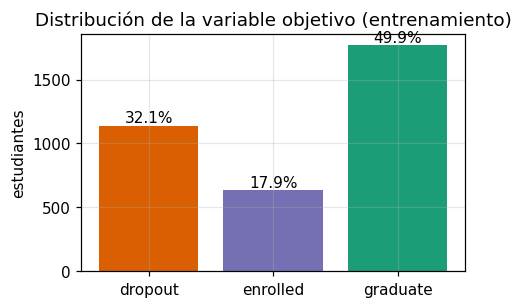

In [4]:
cnt = y.value_counts().reindex(CLASSES)
dist = pd.DataFrame({"n": cnt, "%": (100 * cnt / cnt.sum()).round(1)})
display(dist)
fig, ax = plt.subplots(figsize=(4.5, 2.8))
ax.bar(dist.index, dist["n"], color=["#d95f02", "#7570b3", "#1b9e77"][:len(dist)])
for i, v in enumerate(dist["n"]): ax.text(i, v, f"{dist['%'].iloc[i]}%", ha="center", va="bottom")
ax.set_title("Distribución de la variable objetivo (entrenamiento)"); ax.set_ylabel("estudiantes"); plt.show()

Codificación de la etiqueta. VotingClassifier, StackingClassifier y XGBoost trabajan internamente con etiquetas enteras, así que desde aquí el objetivo de trabajo es yi (0 = dropout, 1 = enrolled, 2 = graduate, el orden alfabético de CLASSES). Los pesos por clase se escriben con esos enteros: {1: 2.0} es el {"enrolled": 2.0} de la Práctica 3. Los pliegues son exactamente los de la Práctica 3.

In [5]:
CLASS2ID = {c: i for i, c in enumerate(CLASSES)}
yi = y.map(CLASS2ID).astype(int)
POS = CLASS2ID["enrolled"]               
CW_E2 = {POS: 2.0}                         
print(CLASS2ID, "| clase minoritaria:", CLASSES[POS])

{'dropout': 0, 'enrolled': 1, 'graduate': 2} | clase minoritaria: enrolled


## Los cinco clasificadores base de la Práctica 3 (sin repetir su optimización)

Se reconstruyen con el preprocesamiento y los hiperparámetros que resultaron mejores en la Práctica 3. El preprocesamiento (FeatureAdder, codificación, escalado, selección de atributos) forma parte de cada Pipeline.

| Clasificador | Preprocesamiento | Hiperparámetros fijados (Práctica 3) |
|---|---|---|
| Árbol | one-hot + sin escalar | `criterion=log_loss`, `max_depth=12`, `min_samples_leaf=36`, `min_samples_split=25`, `ccp_alpha=4.46e-4`, `class_weight={enrolled: 2}` |
| Naive Bayes | categórico: ordinal + 6 bins por cuantiles + `SelectKBest(chi2, k=16)` | `CategoricalNB(alpha=0.0576, fit_prior=True)` |
| kNN | one-hot + estandarizar + `SelectKBest(f_classif, k=20)` | `k=25`, `metric=cosine`, `weights=uniform` |
| SVM | one-hot + estandarizar | `kernel=rbf`, `C=30.31`, `gamma=1.60e-3`, `class_weight={enrolled: 2}` |
| Regresión logística | one-hot + estandarizar | `C=0.1758`, regularización L2, `class_weight={enrolled: 2}`, solver `saga` |

In [6]:
class FeatureAdder(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        for s in ("1st", "2nd"):
            p = f"curricular_units_{s}_sem_"
            if all(p + k in X.columns for k in ("enrolled", "approved", "evaluations")):
                enr = X[p + "enrolled"].replace(0, np.nan)
                ev  = X[p + "evaluations"].replace(0, np.nan)
                X[f"tasa_aprob_{s}"]      = (X[p + "approved"] / enr).fillna(0.0)
                X[f"tasa_eval_{s}"]       = (X[p + "evaluations"] / enr).fillna(0.0)
                X[f"tasa_aprob_eval_{s}"] = (X[p + "approved"] / ev).fillna(0.0)
        return X

class SafeOrdinalEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, min_frequency=20):
        self.min_frequency = min_frequency
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.maps_ = []
        for j in range(X.shape[1]):
            vc = X.iloc[:, j].value_counts()
            keep = vc[vc >= self.min_frequency].index
            self.maps_.append({v: i + 1 for i, v in enumerate(keep)})
        return self
    def transform(self, X):
        X = pd.DataFrame(X)
        out = np.zeros(X.shape, dtype=int)
        for j, m in enumerate(self.maps_):
            out[:, j] = X.iloc[:, j].map(m).fillna(0).astype(int).to_numpy()
        return out

class SafeCategoricalNB(ClassifierMixin, BaseEstimator):
    def __init__(self, alpha=1.0, fit_prior=True):
        self.alpha = alpha
        self.fit_prior = fit_prior
    def fit(self, X, y):
        X = np.clip(np.asarray(X).astype(int), 0, None)
        self.n_cat_ = X.max(axis=0) + 1
        self.nb_ = CategoricalNB(alpha=self.alpha, fit_prior=self.fit_prior, min_categories=self.n_cat_).fit(X, y)
        self.classes_ = self.nb_.classes_
        return self
    def _p(self, X):
        return np.clip(np.asarray(X).astype(int), 0, self.n_cat_ - 1)
    def predict(self, X):
        return self.nb_.predict(self._p(X))
    def predict_proba(self, X):
        return self.nb_.predict_proba(self._p(X))

def sel_nominal(df): return [c for c in df.columns if c in NOMINAL]
def sel_numeric(df): return [c for c in df.columns if c not in NOMINAL]
def sel_binary(df):  return [c for c in df.columns if c in BINARY]
def sel_cont(df):    return [c for c in df.columns if c not in NOMINAL and c not in BINARY]

def OHE():
    return OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False)

def prep_tree():     
    return ColumnTransformer([("nom", OHE(), sel_nominal), ("num", "passthrough", sel_numeric)], verbose_feature_names_out=False)
def prep_scaled():   
    return ColumnTransformer([("nom", OHE(), sel_nominal), ("num", StandardScaler(), sel_numeric)], verbose_feature_names_out=False)
def prep_gauss(power):
    num = PowerTransformer(method="yeo-johnson") if power else StandardScaler()
    return ColumnTransformer([("nom", OHE(), sel_nominal), ("num", num, sel_numeric)], verbose_feature_names_out=False)
def prep_complement():
    return ColumnTransformer([("nom", OHE(), sel_nominal), ("num", MinMaxScaler(), sel_numeric)], verbose_feature_names_out=False)
def prep_categorical():
    return ColumnTransformer([("nom", SafeOrdinalEncoder(min_frequency=20), sel_nominal),
                              ("bin", "passthrough", sel_binary),
                              ("cont", KBinsDiscretizer(n_bins=5, encode="ordinal", strategy="quantile"), sel_cont)])

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(X, y))
print("Tamaños de validación por pliegue:", [len(v) for _, v in folds])

Tamaños de validación por pliegue: [708, 708, 708, 708, 707]


In [7]:
FEAT = ("feat", FeatureAdder())

def make_base(svm_proba=False):
    lr_kw = dict(l1_ratio=0.0) if SK_VER >= (1, 8) else dict(penalty="l2")
    svc = SVC(kernel="rbf", C=30.30549375591522, gamma=0.0015977662354833878, class_weight=CW_E2,
              cache_size=1000, max_iter=100000, random_state=SEED)
    svm_clf = CalibratedClassifierCV(svc, method="sigmoid", cv=3) if svm_proba else svc
    nb_prep = prep_categorical().set_params(cont__n_bins=6, cont__strategy="quantile")
    return {
        "Árbol": Pipeline([FEAT, ("prep", prep_tree()), ("clf", DecisionTreeClassifier(
            criterion="log_loss", max_depth=12, min_samples_leaf=36, min_samples_split=25,
            ccp_alpha=0.00044578143689879266, max_features=None, class_weight=CW_E2, random_state=SEED))]),
        "Naive Bayes": Pipeline([FEAT, ("prep", nb_prep), ("sel", SelectKBest(chi2, k=16)),
                                 ("clf", SafeCategoricalNB(alpha=0.057624872164786026, fit_prior=True))]),
        "kNN": Pipeline([FEAT, ("prep", prep_scaled()), ("sel", SelectKBest(f_classif, k=20)),
                         ("clf", KNeighborsClassifier(n_neighbors=25, weights="uniform", metric="cosine"))]),
        "SVM": Pipeline([FEAT, ("prep", prep_scaled()), ("clf", svm_clf)]),
        "Regresión logística": Pipeline([FEAT, ("prep", prep_scaled()), ("clf", LogisticRegression(
            solver="saga", max_iter=500, tol=1e-3, C=0.17583640270008521, class_weight=CW_E2, **lr_kw))]),
    }

BASE = make_base()
print(list(BASE))

['Árbol', 'Naive Bayes', 'kNN', 'SVM', 'Regresión logística']


### Función común de evaluación

Todos los modelos de la práctica se evalúan con cross_validate sobre los mismos cinco pliegues. De cada corrida salen: el F1 macro por pliegue (media ± desviación), la sensibilidad de la clase minoritaria (recall de esa clase en cada pliegue, promediado) y el tiempo medio de entrenamiento por pliegue. Con n_jobs=-1 se entrenan pliegues en paralelo, por lo que los tiempos son de reloj de pared de un pliegue con CPU compartida: sirven para comparar órdenes de magnitud, no como mediciones exactas.

In [8]:
def bench(name, est, Xd, yd, cv, pos, n_jobs=-1, config=""):
    sc = {"f1_macro": "f1_macro", "sens": make_scorer(recall_score, labels=[pos], average="macro")}
    r = cross_validate(est, Xd, yd, cv=cv, scoring=sc, n_jobs=n_jobs, error_score="raise")
    f1 = r["test_f1_macro"]
    return {"modelo": name, "F1 media": f1.mean(), "F1 desv.": f1.std(ddof=1), "sensibilidad": r["test_sens"].mean(),
            "t. entrenamiento (s)": r["fit_time"].mean(), "configuración": config, "_folds": f1}

def fmt_table(rows, sens_name):
    t = pd.DataFrame(rows).sort_values("F1 media", ascending=False).reset_index(drop=True)
    out = pd.DataFrame({"modelo": t["modelo"],
                        "F1 macro (media ± desv.)": [f"{m:.3f} ± {s:.3f}" for m, s in zip(t["F1 media"], t["F1 desv."])],
                        sens_name: t["sensibilidad"].round(3),
                        "t. entrenamiento (s)": t["t. entrenamiento (s)"].round(2),
                        "configuración": t["configuración"]})
    out.index = out.index + 1
    return t, out

ROWS = []                                         
t0 = time.perf_counter()
for n, m in BASE.items():
    ROWS.append(bench(n, m, X, yi, folds, POS, config="Práctica 3"))
tab_base, show = fmt_table(ROWS, "sensibilidad enrolled")
display(show.drop(columns="configuración"))
print(f"({time.perf_counter() - t0:.0f} s)  | referencia Práctica 3 (F1 macro): SVM 0.687, Reg. logística 0.685, Árbol 0.657, Naive Bayes 0.656, kNN 0.640")

,modelo,F1 macro (media ± desv.),sensibilidad enrolled,t. entrenamiento (s)
1,SVM,0.687 ± 0.012,0.562,0.36
2,Regresión logística,0.685 ± 0.006,0.529,0.35
3,Árbol,0.657 ± 0.016,0.562,0.08
4,Naive Bayes,0.656 ± 0.018,0.494,0.06
5,kNN,0.640 ± 0.019,0.255,0.05


(8 s)  | referencia Práctica 3 (F1 macro): SVM 0.687, Reg. logística 0.685, Árbol 0.657, Naive Bayes 0.656, kNN 0.640


# Varianza: un árbol sin límite de profundidad contra bagging

Un árbol sin límite de profundidad crece hasta separar por completo el entrenamiento: tiene sesgo bajo pero varianza alta, porque cambiar unas decenas de estudiantes cambia los cortes y con ellos las predicciones. Bagging (bootstrap aggregating) entrena muchos árboles de ese tipo, cada uno con una muestra bootstrap del entrenamiento, y promedia sus votos.

Para la curva contra el número de árboles se usa BaggingClassifier(warm_start=True): en cada pliegue se parte de 1 árbol y se van añadiendo árboles hasta 400 sin reentrenar los anteriores, midiendo el F1 macro de validación en 1, 5, 10, 20, 50, 100, 200, 300 y 400 árboles. El preprocesamiento (FeatureAdder + one-hot) se ajusta una vez por pliegue con el entrenamiento del pliegue.

Árbol sin límite de profundidad: F1 macro = 0.591 ± 0.012
Bagging con 400 árboles:      F1 macro = 0.662 ± 0.021


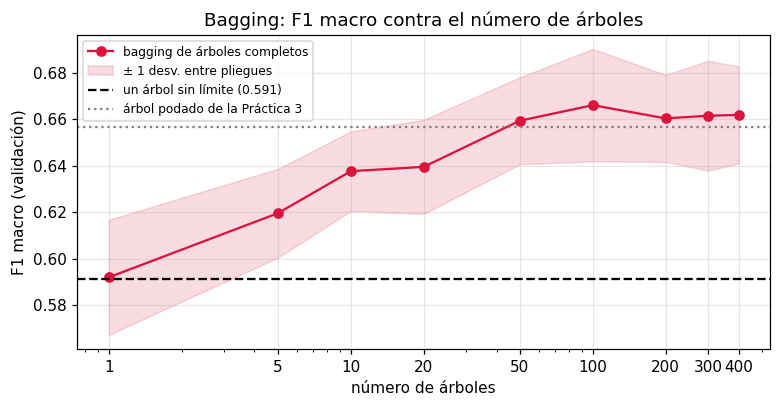

In [9]:
N_TREES = [1, 5, 10, 20, 50, 100, 200, 300, 400]
if QUICK: N_TREES = [1, 5, 10, 20, 50]

def prep_fold(tr, va):
    pre = Pipeline([FEAT, ("prep", prep_tree())]).fit(X.iloc[tr])
    return pre.transform(X.iloc[tr]), pre.transform(X.iloc[va]), yi.iloc[tr].to_numpy(), yi.iloc[va].to_numpy()

def bagging_curve_fold(tr, va):
    Xt, Xv, yt, yv = prep_fold(tr, va)
    tree = DecisionTreeClassifier(random_state=SEED)                       
    f_tree = f1_score(yv, tree.fit(Xt, yt).predict(Xv), average="macro")
    bag = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=SEED), n_estimators=1, warm_start=True,
                            random_state=SEED, n_jobs=1)
    out, t_acc = [], 0.0
    for k in N_TREES:
        bag.set_params(n_estimators=k)
        t1 = time.perf_counter(); bag.fit(Xt, yt); t_acc += time.perf_counter() - t1
        out.append(f1_score(yv, bag.predict(Xv), average="macro"))
    return f_tree, np.array(out), t_acc

res = Parallel(n_jobs=-1)(delayed(bagging_curve_fold)(tr, va) for tr, va in folds)
f_tree = np.array([r[0] for r in res]); curve_bag = np.vstack([r[1] for r in res])
print(f"Árbol sin límite de profundidad: F1 macro = {f_tree.mean():.3f} ± {f_tree.std(ddof=1):.3f}")
print(f"Bagging con {N_TREES[-1]} árboles:      F1 macro = {curve_bag[:, -1].mean():.3f} ± {curve_bag[:, -1].std(ddof=1):.3f}")

fig, ax = plt.subplots(figsize=(7.2, 3.8))
m, s = curve_bag.mean(0), curve_bag.std(0, ddof=1)
ax.plot(N_TREES, m, "o-", color="crimson", label="bagging de árboles completos")
ax.fill_between(N_TREES, m - s, m + s, color="crimson", alpha=.15, label="± 1 desv. entre pliegues")
ax.axhline(f_tree.mean(), color="k", ls="--", label=f"un árbol sin límite ({f_tree.mean():.3f})")
ax.axhline(tab_base.set_index("modelo").loc["Árbol", "F1 media"], color="gray", ls=":", label="árbol podado de la Práctica 3")
ax.set_xscale("log"); ax.set_xticks(N_TREES); ax.set_xticklabels(N_TREES)
ax.set_xlabel("número de árboles"); ax.set_ylabel("F1 macro (validación)"); ax.set_title("Bagging: F1 macro contra el número de árboles")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

BAG_T = np.mean([r[2] for r in res]) / 1.0
ROWS.append({"modelo": "Árbol sin límite", "F1 media": f_tree.mean(), "F1 desv.": f_tree.std(ddof=1), "sensibilidad": np.nan,
             "t. entrenamiento (s)": np.nan, "configuración": "max_depth=None", "_folds": f_tree})
ROWS.append({"modelo": f"Bagging ({N_TREES[-1]} árboles)", "F1 media": curve_bag[:, -1].mean(), "F1 desv.": curve_bag[:, -1].std(ddof=1),
             "sensibilidad": np.nan, "t. entrenamiento (s)": np.nan, "configuración": "árboles sin límite, bootstrap", "_folds": curve_bag[:, -1]})

**¿Qué reduce bagging, y por qué?** La hipótesis es la varianza. Para comprobarla directamente (y no solo mirar el F1) se simula el "cambio de muestra": en el pliegue 1 se extraen 12 submuestras distintas (70 % del entrenamiento, sin reemplazo), se entrena en cada una un árbol sin límite y un bagging de 100 árboles, y se mide, sobre los mismos estudiantes de validación, qué tan inestable es la predicción. La *inestabilidad* de un estudiante es 1 − (fracción de modelos que votan por su clase más votada): 0 significa que todas las submuestras predicen lo mismo; valores altos significan que la predicción depende de la muestra de entrenamiento, que es la varianza.

In [10]:
tr0, va0 = folds[0]
Xt0, Xv0, yt0, yv0 = prep_fold(tr0, va0)
R = 4 if QUICK else 12
rng = np.random.RandomState(SEED)
def one_resample(r):
    idx = np.random.RandomState(SEED + r).choice(len(Xt0), int(.7 * len(Xt0)), replace=False)
    t = DecisionTreeClassifier(random_state=r).fit(Xt0[idx], yt0[idx])
    b = BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100, random_state=r, n_jobs=1).fit(Xt0[idx], yt0[idx])
    return t.predict(Xv0), b.predict(Xv0)
out = Parallel(n_jobs=-1)(delayed(one_resample)(r) for r in range(R))
P_tree = np.vstack([o[0] for o in out]); P_bag = np.vstack([o[1] for o in out])

def instability(P):
    votes = np.stack([(P == c).mean(0) for c in range(len(CLASSES))])
    return float(np.mean(1 - votes.max(0)))
var_tab = pd.DataFrame({
    "inestabilidad de la predicción": [instability(P_tree), instability(P_bag)],
    "F1 macro medio sobre submuestras": [np.mean([f1_score(yv0, p, average="macro") for p in P]) for P in (P_tree, P_bag)],
    "desv. del F1 entre submuestras": [np.std([f1_score(yv0, p, average="macro") for p in P], ddof=1) for P in (P_tree, P_bag)],
}, index=["árbol sin límite", "bagging (100 árboles)"])
display(var_tab.round(4))

,inestabilidad de la predicción,F1 macro medio sobre submuestras,desv. del F1 entre submuestras
árbol sin límite,0.2407,0.5648,0.0176
bagging (100 árboles),0.0733,0.6362,0.0134


**Resultado.** Bagging baja la inestabilidad de la predicción de 0.241 a 0.073 (70 % menos) y sube el F1 macro medio de 0.565 a 0.636.

En el esquema sesgo-varianza, el error esperado de un modelo es sesgo² + varianza + ruido. Promediar *B* modelos con varianza σ² y correlación ρ entre ellos deja una varianza ρσ² + (1 − ρ)σ²/B. El segundo término desaparece al crecer *B* (por eso la curva se aplana hacia 100-200 árboles); el primero no, y por eso bagging no puede dar más de lo que permite la correlación entre árboles (que comparten los mismos atributos dominantes).

El **sesgo** casi no cambia: cada árbol completo sigue siendo un estimador de bajo sesgo, y promediar no lo corrige.

# Sesgo: un tocón contra AdaBoost con tocones

Un tocón (árbol de profundidad 1) es un clasificador con sesgo alto y varianza baja: solo puede hacer un corte sobre un atributo, así que no puede representar la frontera. AdaBoost entrena tocones en secuencia; cada ronda da más peso a los estudiantes que las anteriores clasificaron mal, de modo que el conjunto final es una combinación ponderada de cortes que aproxima fronteras complejas. Con staged_predict() se obtiene la predicción tras cada ronda sin reentrenar, hasta 400 rondas; se grafica también el F1 macro en entrenamiento, que es la señal más directa del sesgo.

Tocón:                F1 macro validación = 0.508 ± 0.013 | entrenamiento = 0.508
AdaBoost (400 rondas): F1 macro validación = 0.653 ± 0.018 | entrenamiento = 0.674


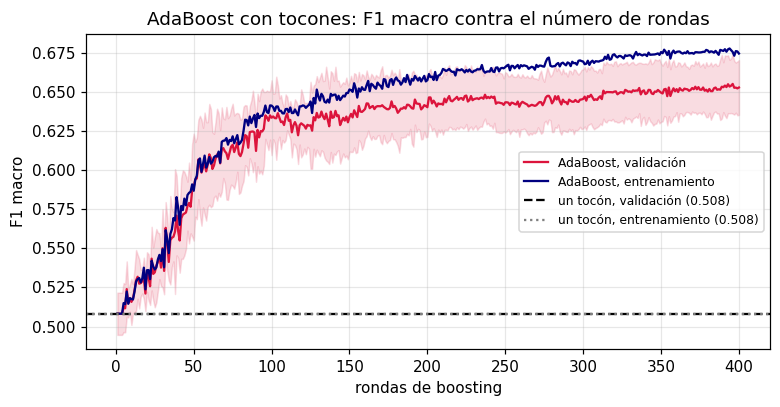

In [11]:
N_ROUNDS = 60 if QUICK else 400

def ada_fold(tr, va):
    Xt, Xv, yt, yv = prep_fold(tr, va)
    stump = DecisionTreeClassifier(max_depth=1, random_state=SEED)
    f_stump_v = f1_score(yv, stump.fit(Xt, yt).predict(Xv), average="macro")
    f_stump_t = f1_score(yt, stump.predict(Xt), average="macro")
    ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, random_state=SEED),
                             n_estimators=N_ROUNDS, learning_rate=1.0, random_state=SEED).fit(Xt, yt)
    cv_ = [f1_score(yv, p, average="macro") for p in ada.staged_predict(Xv)]
    ct_ = [f1_score(yt, p, average="macro") for p in ada.staged_predict(Xt)]
    return f_stump_v, f_stump_t, np.array(cv_), np.array(ct_)

res = Parallel(n_jobs=-1)(delayed(ada_fold)(tr, va) for tr, va in folds)
f_stump = np.array([r[0] for r in res]); f_stump_tr = np.array([r[1] for r in res])
ada_val = np.vstack([r[2] for r in res]); ada_trn = np.vstack([r[3] for r in res])
rounds = np.arange(1, ada_val.shape[1] + 1)
print(f"Tocón:                F1 macro validación = {f_stump.mean():.3f} ± {f_stump.std(ddof=1):.3f} | entrenamiento = {f_stump_tr.mean():.3f}")
print(f"AdaBoost ({rounds[-1]} rondas): F1 macro validación = {ada_val[:, -1].mean():.3f} ± {ada_val[:, -1].std(ddof=1):.3f} | entrenamiento = {ada_trn[:, -1].mean():.3f}")

fig, ax = plt.subplots(figsize=(7.2, 3.8))
mv, sv = ada_val.mean(0), ada_val.std(0, ddof=1)
ax.plot(rounds, mv, color="crimson", label="AdaBoost, validación")
ax.fill_between(rounds, mv - sv, mv + sv, color="crimson", alpha=.15)
ax.plot(rounds, ada_trn.mean(0), color="navy", label="AdaBoost, entrenamiento")
ax.axhline(f_stump.mean(), color="k", ls="--", label=f"un tocón, validación ({f_stump.mean():.3f})")
ax.axhline(f_stump_tr.mean(), color="gray", ls=":", label=f"un tocón, entrenamiento ({f_stump_tr.mean():.3f})")
ax.set_xlabel("rondas de boosting"); ax.set_ylabel("F1 macro"); ax.set_title("AdaBoost con tocones: F1 macro contra el número de rondas")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

best_round = int(mv.argmax()) + 1
ROWS.append({"modelo": "Tocón (profundidad 1)", "F1 media": f_stump.mean(), "F1 desv.": f_stump.std(ddof=1), "sensibilidad": np.nan,
             "t. entrenamiento (s)": np.nan, "configuración": "max_depth=1", "_folds": f_stump})
ROWS.append({"modelo": f"AdaBoost ({rounds[-1]} rondas)", "F1 media": ada_val[:, -1].mean(), "F1 desv.": ada_val[:, -1].std(ddof=1),
             "sensibilidad": np.nan, "t. entrenamiento (s)": np.nan, "configuración": f"tocones, lr=1 (máx. de la curva en la ronda {best_round})",
             "_folds": ada_val[:, -1]})

¿Qué reduce boosting, y por qué? El sesgo. Un tocón queda en 0.508 de F1 macro tanto en validación como en entrenamiento (0.508): no se ajusta ni a los datos que vio, que es la firma del subajuste. AdaBoost pasa a 0.653 en validación (+0.145) y a 0.674 en entrenamiento: cada ronda corrige los errores de las anteriores, así que el modelo final representa una frontera que ningún tocón puede.

La brecha entre entrenamiento y validación (0.022) es el precio: boosting reduce el sesgo a costa de acercarse a la varianza, y por eso la curva de validación se aplana (el máximo está en la ronda 396) mientras que la de entrenamiento sigue subiendo.

Es la contraparte de bagging: bagging promedia modelos de bajo sesgo y alta varianza para quitar varianza; boosting suma modelos de sesgo alto y varianza baja para quitar sesgo.

# Combinar los cinco clasificadores base

Tres formas de combinar los mismos cinco Pipelines:

* Votación dura: cada clasificador vota una clase y gana la más votada.
* Votación suave: se promedian las probabilidades de los cinco. Necesita predict_proba en todos; el SVM no la trae, así que se envuelve en CalibratedClassifierCV (sigmoide, 3 pliegues internos). Como la calibración es parte del modelo, se ajusta dentro de cada partición de entrenamiento de la validación cruzada externa; el pliegue de validación nunca interviene.
* Stacking: las probabilidades de los cinco, obtenidas con validación cruzada interna (5 pliegues estratificados sobre el entrenamiento, para que el meta-modelo no vea predicciones "optimistas" del propio entrenamiento), son las entradas de un meta-modelo de regresión logística.

La votación dura usa el SVM sin calibrar (solo necesita su voto); la suave y el stacking usan el SVM calibrado. Se evalúan con cross_validate y los mismos cinco pliegues.

In [12]:
def voting(kind):
    est = make_base(svm_proba=(kind == "soft"))
    return VotingClassifier(list(est.items()), voting=kind, n_jobs=1)

def stacking():
    est = make_base(svm_proba=True)
    return StackingClassifier(list(est.items()), final_estimator=LogisticRegression(max_iter=2000),
                              cv=StratifiedKFold(5, shuffle=True, random_state=SEED), stack_method="predict_proba", n_jobs=1)

t0 = time.perf_counter()
for name, est in [("Votación dura", voting("hard")), ("Votación suave", voting("soft")), ("Stacking (meta: logística)", stacking())]:
    ROWS.append(bench(name, est, X, yi, folds, POS, config="5 base de la Práctica 3"))
tab_ens, show = fmt_table([r for r in ROWS if r["modelo"] in ("Votación dura", "Votación suave", "Stacking (meta: logística)")], "sensibilidad enrolled")
display(show.drop(columns="configuración"))
best_base = tab_base.iloc[0]
print(f"Mejor clasificador base: {best_base['modelo']} {best_base['F1 media']:.3f} ± {best_base['F1 desv.']:.3f}   ({time.perf_counter() - t0:.0f} s)")

,modelo,F1 macro (media ± desv.),sensibilidad enrolled,t. entrenamiento (s)
1,Votación dura,0.693 ± 0.004,0.521,0.79
2,Votación suave,0.679 ± 0.011,0.444,1.33
3,Stacking (meta: logística),0.666 ± 0.013,0.340,6.99


Mejor clasificador base: SVM 0.687 ± 0.012   (10 s)


### Correlación de los errores entre los cinco clasificadores

Un ensamble solo gana si sus miembros se equivocan en estudiantes **distintos**. Con las predicciones de validación cruzada de cada clasificador (cada estudiante es predicho por un modelo que no lo vio) se construye, para cada uno, el indicador de error (1 si falla). Se mide la correlación entre indicadores y se compara cuántos estudiantes fallan *todos* los clasificadores con lo que ocurriría si los errores fueran independientes.

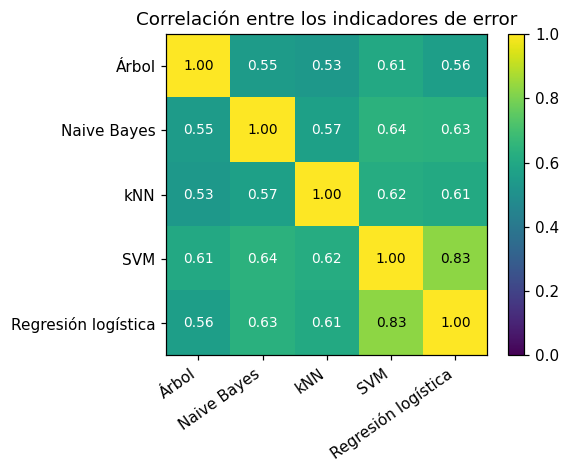

In [13]:
OOF = {n: cross_val_predict(m, X, yi, cv=folds, n_jobs=-1) for n, m in BASE.items()}
E = pd.DataFrame({n: (p != yi.to_numpy()).astype(int) for n, p in OOF.items()})
C = E.corr()
fig, ax = plt.subplots(figsize=(5.4, 4.4))
im = ax.imshow(C.values, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(5)); ax.set_yticks(range(5)); ax.set_xticklabels(C.columns, rotation=35, ha="right"); ax.set_yticklabels(C.columns)
for i in range(5):
    for j in range(5): ax.text(j, i, f"{C.values[i, j]:.2f}", ha="center", va="center", color="w" if C.values[i, j] < .7 else "k", fontsize=9)
ax.grid(False); plt.colorbar(im, fraction=.046); ax.set_title("Correlación entre los indicadores de error"); plt.tight_layout(); plt.show()

off = C.values[np.triu_indices(5, 1)]
err = E.mean()
all_fail = float((E.sum(1) == 5).mean()); indep = float(np.prod(err.values))
maj_fail = float((E.sum(1) >= 3).mean()); any_ok = float((E.sum(1) < 5).mean())

Lectura. La correlación media entre errores es 0.62 (mín. 0.53, máx. 0.83). Los cinco fallan a la vez en 13.3 % de los estudiantes; si fueran independientes serían 0.16 %. La mayoría (≥ 3 de 5) falla en 25.9 %, así que ese es el techo práctico de una votación por mayoría. El "oráculo" (al menos uno acierta) llegaría a 86.7 % de exactitud, muy por encima de cualquier miembro (mejor error individual: 26.1 %).

Implicación: los errores están muy correlacionados. Los cinco se equivocan en los mismos estudiantes (los que están en la frontera entre dropout, enrolled y graduate, y para los que el 1er semestre no contiene la señal), de modo que la parte del error que comparten no se puede promediar. El margen de mejora de votar o apilar es la diferencia entre el error de un miembro y esa parte compartida, y por eso se esperan ganancias de décimas de punto, no de puntos.

# Bagging optimizado: Random Forest y Extra-Trees

Random Forest añade a bagging un sorteo aleatorio de atributos en cada corte (max_features), lo que decorrelaciona los árboles y baja el término ρσ² de la sección 3. Extra-Trees va un paso más allá: además sortea el umbral de cada corte (más sesgo, aún menos varianza) y por defecto no usa bootstrap.

Búsqueda aleatoria (RandomizedSearchCV, scoring="f1_macro", los mismos cinco pliegues, N_ITER ≥ 50 configuraciones por modelo). Se fijan 300 árboles (la curva de la sección 3 muestra que ya no aportan más) y se exploran:

| Hiperparámetro | Rango |
|---|---|
| max_features | {sqrt, log2, 0.2, 0.35, 0.5} |
| tamaño de hoja / profundidad | min_samples_leaf U{1..20}; max_depth {None, 6, 10, 14, 20} |
| criterion | {gini, entropy, log_loss} |
| class_weight | {None, balanced, balanced_subsample, enrolled×2, enrolled×3} |
| bootstrap | RF: True (con max_samples U[0.5, 1]); Extra-Trees: {True, False} |

In [14]:
CW_ENS = [None, "balanced", "balanced_subsample", {POS: 2.0}, {POS: 3.0}]
N_TREES_SEARCH = 100 if QUICK else 300
common = {"clf__max_features": ["sqrt", "log2", 0.2, 0.35, 0.5], "clf__min_samples_leaf": randint(1, 21),
          "clf__max_depth": [None, 6, 10, 14, 20], "clf__criterion": ["gini", "entropy", "log_loss"], "clf__class_weight": CW_ENS}

pipe_rf = Pipeline([FEAT, ("prep", prep_tree()), ("clf", RandomForestClassifier(n_estimators=N_TREES_SEARCH, bootstrap=True, random_state=SEED, n_jobs=1))])
space_rf = dict(common, clf__max_samples=uniform(0.5, 0.5))
pipe_et = Pipeline([FEAT, ("prep", prep_tree()), ("clf", ExtraTreesClassifier(n_estimators=N_TREES_SEARCH, random_state=SEED, n_jobs=1))])
space_et = dict(common, clf__bootstrap=[True, False])

SEARCH = {}          
def run_search(name, pipe, space, Xd, yd, cv, n_iter=None):
    rs = RandomizedSearchCV(pipe, space, n_iter=n_iter or N_ITER, scoring="f1_macro", cv=cv, n_jobs=-1,
                            random_state=SEED, refit=True, error_score=np.nan)
    t0 = time.perf_counter(); rs.fit(Xd, yd)
    SEARCH[name] = {"search": rs, "time": time.perf_counter() - t0}
    s = rs.cv_results_["mean_test_score"]
    print(f"{name:14s} configs={len(s):3d} (fallidas={int(np.isnan(s).sum())})  mejor F1 macro CV={rs.best_score_:.4f}  búsqueda={SEARCH[name]['time']:.0f} s")
    print("   mejor configuración:", {k.replace('clf__', ''): v for k, v in rs.best_params_.items()})
    return rs

run_search("Random Forest", pipe_rf, space_rf, X, yi, folds)
run_search("Extra-Trees", pipe_et, space_et, X, yi, folds)

Random Forest  configs= 60 (fallidas=0)  mejor F1 macro CV=0.6900  búsqueda=61 s
   mejor configuración: {'class_weight': {1: 2.0}, 'criterion': 'entropy', 'max_depth': 14, 'max_features': 0.2, 'max_samples': np.float64(0.6861413832808716), 'min_samples_leaf': 3}
Extra-Trees    configs= 60 (fallidas=0)  mejor F1 macro CV=0.6899  búsqueda=71 s
   mejor configuración: {'bootstrap': False, 'class_weight': 'balanced_subsample', 'criterion': 'log_loss', 'max_depth': None, 'max_features': 0.2, 'min_samples_leaf': 5}


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'clf__bootstrap': [True, False], 'clf__class_weight': [None, 'balanced', ...], 'clf__criterion': ['gini', 'entropy', ...], 'clf__max_depth': [None, 6, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",60
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 0, ...shape=(2831,)), ...), (array([ 0, ...shape=(2831,)), ...), ...]"
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``

Izquierda de cada gráfica: mejor F1 macro alcanzado (línea) contra el número de configuraciones evaluadas; los puntos son el F1 macro de cada configuración. **Una meseta** significa que las últimas configuraciones ya no mejoran el máximo. Derecha: el F1 macro contra el hiperparámetro más influyente.

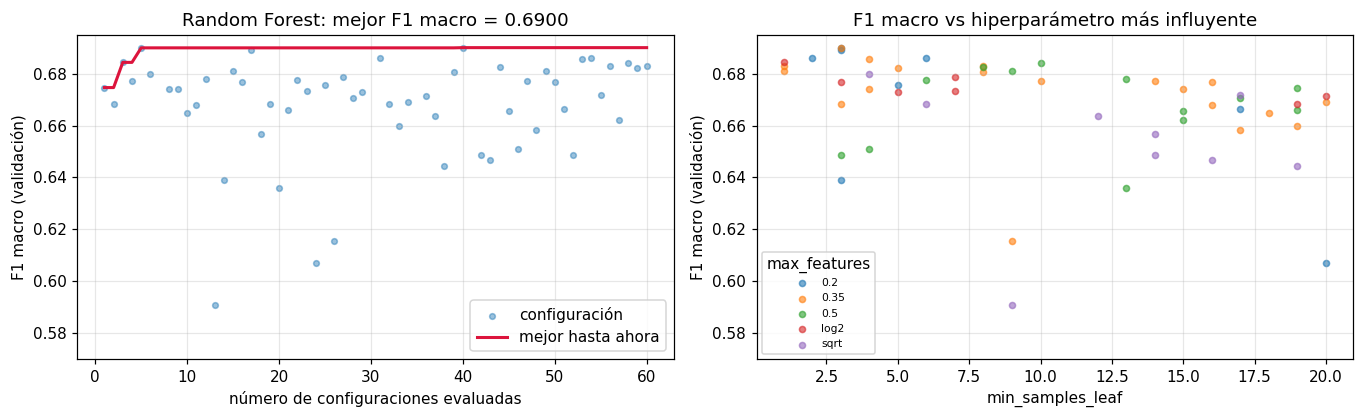

   la mejor configuración apareció en la #40 de 60; mejora del máximo entre la #30 y la #60: +0.0001


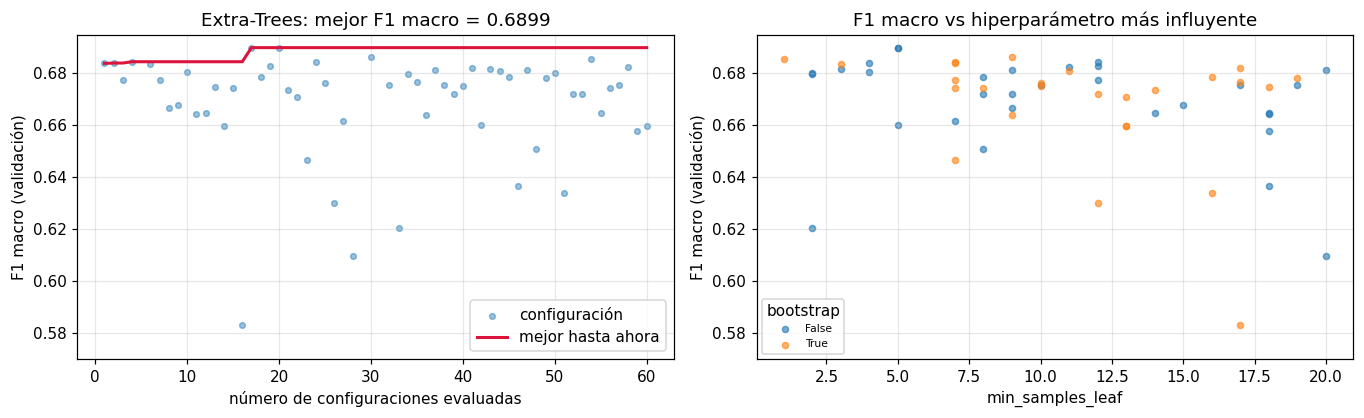

   la mejor configuración apareció en la #17 de 60; mejora del máximo entre la #30 y la #60: +0.0000
--- Random Forest: F1 macro por peso de clase


,n,mejor,media
class_weight,,,
{1: 2.0},14,0.6900,0.6790
{1: 3.0},14,0.6889,0.6673
balanced,9,0.6855,0.6723
balanced_subsample,12,0.6842,0.6748
None,11,0.6510,0.5942


--- Extra-Trees: F1 macro por peso de clase


,n,mejor,media
class_weight,,,
balanced_subsample,17,0.6899,0.6803
{1: 3.0},11,0.6854,0.6695
balanced,8,0.6844,0.6793
{1: 2.0},12,0.6838,0.6731
None,12,0.6599,0.6052


In [15]:
def plateau_figure(name, xcol=None, xlog=False, hue=None, hue_fn=None, xlabel=None):
    res = pd.DataFrame(SEARCH[name]["search"].cv_results_)
    s = res["mean_test_score"].to_numpy(float); ok = ~np.isnan(s); it = np.arange(1, len(s) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.9))
    best_so_far = np.fmax.accumulate(np.where(ok, s, -np.inf))
    ax[0].scatter(it[ok], s[ok], s=14, alpha=.45, label="configuración")
    ax[0].plot(it, best_so_far, color="crimson", lw=2, label="mejor hasta ahora")
    ax[0].set_xlabel("número de configuraciones evaluadas"); ax[0].set_ylabel("F1 macro (validación)")
    ax[0].set_title(f"{name}: mejor F1 macro = {np.nanmax(s):.4f}"); ax[0].legend(loc="lower right")
    ax[0].set_ylim(max(np.nanmin(s), np.nanmax(s) - 0.12), np.nanmax(s) + 0.005)
    h = hue_fn(res) if hue_fn is not None else (res[hue].astype(str) if hue else pd.Series(["todas"] * len(res)))
    h = pd.Series(np.asarray(h).astype(str), index=res.index)
    x = pd.to_numeric(res[xcol], errors="coerce").to_numpy(float)
    for c in sorted(h.unique()):
        m = (h == c).to_numpy() & ok & ~np.isnan(x)
        ax[1].scatter(x[m], s[m], s=16, alpha=.6, label=str(c))
    if xlog: ax[1].set_xscale("log")
    ax[1].set_xlabel(xlabel or xcol); ax[1].legend(fontsize=7, title=hue.split("__")[-1] if hue else None)
    ax[1].set_ylabel("F1 macro (validación)"); ax[1].set_ylim(ax[0].get_ylim()); ax[1].set_title("F1 macro vs hiperparámetro más influyente")
    plt.tight_layout(); plt.show()
    half = len(s) // 2
    print(f"   la mejor configuración apareció en la #{np.nanargmax(s) + 1} de {len(s)}; mejora del máximo entre la #{half} y la #{len(s)}: {np.nanmax(s) - np.nanmax(s[:half]):+.4f}")

plateau_figure("Random Forest", "param_clf__min_samples_leaf", hue="param_clf__max_features", xlabel="min_samples_leaf")
plateau_figure("Extra-Trees", "param_clf__min_samples_leaf", hue="param_clf__bootstrap", xlabel="min_samples_leaf")
for name in ["Random Forest", "Extra-Trees"]:
    res = pd.DataFrame(SEARCH[name]["search"].cv_results_)
    res["class_weight"] = res["param_clf__class_weight"].astype(str)
    print(f"--- {name}: F1 macro por peso de clase")
    display(res.groupby("class_weight")["mean_test_score"].agg(n="count", mejor="max", media="mean").sort_values("mejor", ascending=False).round(4))

# Boosting optimizado: XGBoost y LightGBM

Se eligen XGBoost (árboles por niveles, regularización explícita de los pesos de las hojas) y LightGBM (árboles por hojas, num_leaves). Ambos admiten pesos por clase de forma distinta (LightGBM con class_weight, XGBoost solo con sample_weight), así que un envoltorio mínimo, WeightedBooster, convierte un class_weight en sample_weight dentro de fit; así el peso por clase es un hiperparámetro más de RandomizedSearchCV en ambos.

| Hiperparámetro | XGBoost | LightGBM |
|---|---|---|
| tasa de aprendizaje | learning_rate log-U[0.01, 0.3] | learning_rate log-U[0.01, 0.3] |
| número de árboles | n_estimators U{100..400} | n_estimators U{100..400} |
| profundidad / hojas | max_depth U{2..8} | num_leaves U{4..48}, max_depth {-1, 4, 6, 8} |
| regularización de hojas | reg_lambda log-U[0.1, 50], reg_alpha log-U[1e-3, 5], min_child_weight log-U[1, 20], gamma U[0, 2] | reg_lambda log-U[0.1, 50], reg_alpha log-U[1e-3, 5], min_child_samples U{5..60}, min_split_gain U[0, 1] |
| submuestreo | subsample U[0.5, 1], colsample_bytree U[0.4, 1] | subsample U[0.5, 1] (con subsample_freq=1), colsample_bytree U[0.4, 1] |
| pesos por clase | {None, balanced, enrolled×2, enrolled×3} | {None, balanced, enrolled×2, enrolled×3} |

In [16]:
class WeightedBooster(ClassifierMixin, BaseEstimator):
    def __init__(self, estimator=None, class_weight=None):
        self.estimator = estimator
        self.class_weight = class_weight
    def fit(self, X, y):
        self.est_ = clone(self.estimator)
        sw = None if self.class_weight is None else compute_sample_weight(self.class_weight, y)
        self.est_.fit(X, y, sample_weight=sw)
        self.classes_ = self.est_.classes_
        return self
    def predict(self, X): return self.est_.predict(X)
    def predict_proba(self, X): return self.est_.predict_proba(X)

CW_BOOST = [None, "balanced", {POS: 2.0}, {POS: 3.0}]
xgb = XGBClassifier(tree_method="hist", n_jobs=1, random_state=SEED, verbosity=0, objective="multi:softprob")
lgb = LGBMClassifier(n_jobs=1, random_state=SEED, verbose=-1, subsample_freq=1)
pipe_xgb = Pipeline([FEAT, ("prep", prep_tree()), ("clf", WeightedBooster(xgb))])
pipe_lgb = Pipeline([FEAT, ("prep", prep_tree()), ("clf", WeightedBooster(lgb))])
common_b = {"clf__estimator__learning_rate": loguniform(0.01, 0.3), "clf__estimator__n_estimators": randint(100, 401),
            "clf__estimator__reg_lambda": loguniform(0.1, 50), "clf__estimator__reg_alpha": loguniform(1e-3, 5),
            "clf__estimator__subsample": uniform(0.5, 0.5), "clf__estimator__colsample_bytree": uniform(0.4, 0.6),
            "clf__class_weight": CW_BOOST}
space_xgb = dict(common_b, **{"clf__estimator__max_depth": randint(2, 9), "clf__estimator__min_child_weight": loguniform(1, 20),
                              "clf__estimator__gamma": uniform(0, 2)})
space_lgb = dict(common_b, **{"clf__estimator__num_leaves": randint(4, 49), "clf__estimator__max_depth": [-1, 4, 6, 8],
                              "clf__estimator__min_child_samples": randint(5, 61), "clf__estimator__min_split_gain": uniform(0, 1)})
run_search("XGBoost", pipe_xgb, space_xgb, X, yi, folds)
run_search("LightGBM", pipe_lgb, space_lgb, X, yi, folds)

XGBoost        configs= 60 (fallidas=0)  mejor F1 macro CV=0.6970  búsqueda=38 s
   mejor configuración: {'class_weight': {1: 2.0}, 'estimator__colsample_bytree': np.float64(0.866288149556462), 'estimator__gamma': np.float64(1.11680849947161), 'estimator__learning_rate': np.float64(0.04232796082488226), 'estimator__max_depth': 3, 'estimator__min_child_weight': np.float64(2.6894807886317196), 'estimator__n_estimators': 225, 'estimator__reg_alpha': np.float64(0.06640571912585828), 'estimator__reg_lambda': np.float64(0.10731072936357408), 'estimator__subsample': np.float64(0.7343303209970631)}
LightGBM       configs= 60 (fallidas=0)  mejor F1 macro CV=0.6928  búsqueda=15 s
   mejor configuración: {'class_weight': {1: 2.0}, 'estimator__colsample_bytree': np.float64(0.8081845231526679), 'estimator__learning_rate': np.float64(0.04628518674713462), 'estimator__max_depth': 4, 'estimator__min_child_samples': 8, 'estimator__min_split_gain': np.float64(0.9422017556848528), 'estimator__n_estimator

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...erbose=-1)))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'clf__class_weight': [None, 'balanced', ...], 'clf__estimator__colsample_bytree': <scipy.stats....0026C1EAD5D90>, 'clf__estimator__learning_rate': <scipy.stats....0026C202582D0>, 'clf__estimator__max_depth': [-1, 4, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",60
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 0, ...shape=(2831,)), ...), (array([ 0, ...shape=(2831,)), ...), ...]"
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will no

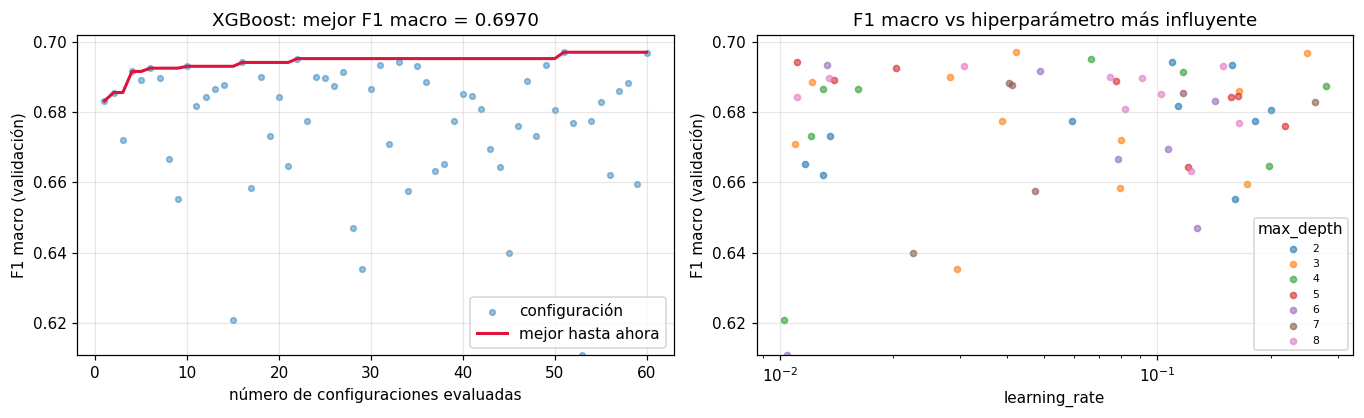

   la mejor configuración apareció en la #51 de 60; mejora del máximo entre la #30 y la #60: +0.0018


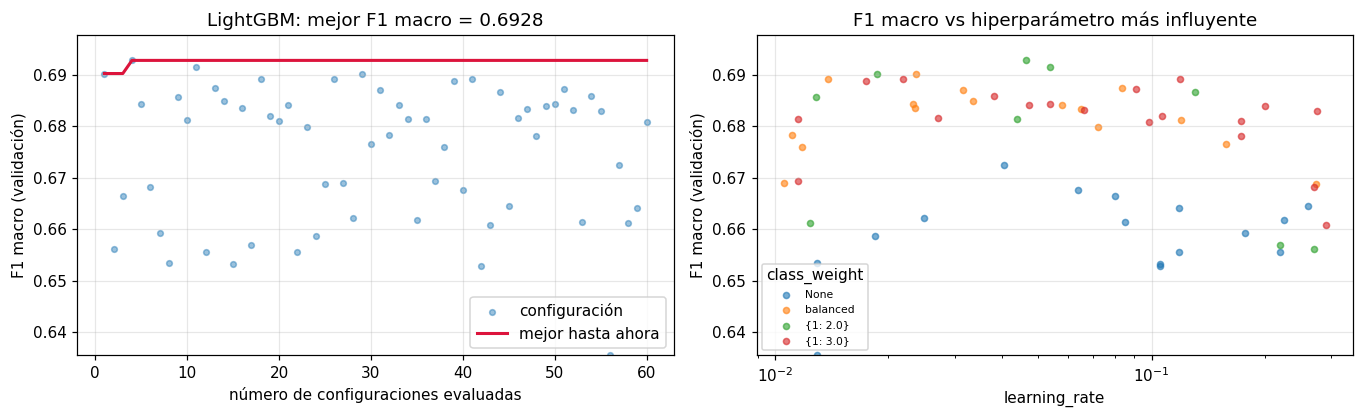

   la mejor configuración apareció en la #4 de 60; mejora del máximo entre la #30 y la #60: +0.0000
--- XGBoost: F1 macro por peso de clase


,n,mejor,media
class_weight,,,
{1: 2.0},18,0.6970,0.6867
balanced,15,0.6952,0.6850
{1: 3.0},13,0.6930,0.6822
None,14,0.6721,0.6511


--- LightGBM: F1 macro por peso de clase


,n,mejor,media
class_weight,,,
{1: 2.0},9,0.6928,0.6781
balanced,16,0.6902,0.6815
{1: 3.0},19,0.6892,0.6812
None,16,0.6725,0.6591


In [17]:
plateau_figure("XGBoost", "param_clf__estimator__learning_rate", xlog=True, hue="param_clf__estimator__max_depth", xlabel="learning_rate")
plateau_figure("LightGBM", "param_clf__estimator__learning_rate", xlog=True, hue="param_clf__class_weight", xlabel="learning_rate")
for name in ["XGBoost", "LightGBM"]:
    res = pd.DataFrame(SEARCH[name]["search"].cv_results_)
    res["class_weight"] = res["param_clf__class_weight"].astype(str)
    print(f"--- {name}: F1 macro por peso de clase")
    display(res.groupby("class_weight")["mean_test_score"].agg(n="count", mejor="max", media="mean").sort_values("mejor", ascending=False).round(4))

# Tabla de todos los modelos

Cada modelo optimizado se reentrena en los cinco pliegues con su mejor configuración para obtener el F1 macro por pliegue y el tiempo de entrenamiento (con `cross_validate`, como el resto). El máximo de una búsqueda es optimista, porque la configuración se eligió justo por ser la mejor en esos pliegues; por eso se añade una columna de control, el F1 macro del mismo modelo en pliegues nuevos (3 × 5, otra semilla). No es un conjunto de prueba independiente, es una comprobación.

In [18]:
fresh = list(RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=1 if QUICK else 3, random_state=SEED + 1).split(X, yi))
def short(d):
    return ", ".join(f"{k.replace('clf__estimator__', '').replace('clf__', '')}={v:.4g}" if isinstance(v, (float, np.floating))
                     else f"{k.replace('clf__estimator__', '').replace('clf__', '')}={v}" for k, v in d.items())
FRESH = {}
for name, d in SEARCH.items():
    best = d["search"].best_estimator_
    row = bench(name + " (optimizado)", clone(best), X, yi, folds, POS, config=short(d["search"].best_params_))
    row["t. búsqueda (s)"] = d["time"]
    ROWS.append(row)
    FRESH[row["modelo"]] = cross_validate(clone(best), X, yi, cv=fresh, scoring="f1_macro", n_jobs=-1)["test_score"].mean()

tab_all, show = fmt_table(ROWS, "sensibilidad enrolled")
show["F1 pliegues nuevos"] = [FRESH.get(m, np.nan) for m in tab_all["modelo"]]
show["F1 pliegues nuevos"] = show["F1 pliegues nuevos"].round(3)
pd.set_option("display.max_colwidth", 140)
display(show)
BEST1 = tab_all.iloc[0]["modelo"]
print("Mejor modelo de la Parte 1:", BEST1)
print("(sensibilidad y tiempo no se calculan para las curvas de las secciones 3 y 4, que se evalúan por separado; ver las filas del bagging/AdaBoost fijos)")

,modelo,F1 macro (media ± desv.),sensibilidad enrolled,t. entrenamiento (s),configuración,F1 pliegues nuevos
1,XGBoost (optimizado),0.697 ± 0.012,0.562,0.83,"class_weight={1: 2.0}, colsample_bytree=0.8663, gamma=1.117, learning_rate=0.04233, max_depth=3, min_child_weight=2.689, n_estimators=22...",0.697
2,Votación dura,0.693 ± 0.004,0.521,0.79,5 base de la Práctica 3,NaN
3,LightGBM (optimizado),0.693 ± 0.012,0.559,0.16,"class_weight={1: 2.0}, colsample_bytree=0.8082, learning_rate=0.04629, max_depth=4, min_child_samples=8, min_split_gain=0.9422, n_estima...",0.693
4,Random Forest (optimizado),0.690 ± 0.017,0.510,1.82,"class_weight={1: 2.0}, criterion=entropy, max_depth=14, max_features=0.2, max_samples=0.6861, min_samples_leaf=3",0.686
5,Extra-Trees (optimizado),0.690 ± 0.014,0.542,2.31,"bootstrap=False, class_weight=balanced_subsample, criterion=log_loss, max_depth=None, max_features=0.2, min_samples_leaf=5",0.687
6,SVM,0.687 ± 0.012,0.562,0.36,Práctica 3,NaN
7,Regresión logística,0.685 ± 0.006,0.529,0.35,Práctica 3,NaN
8,Votación suave,0.679 ± 0.011,0.444,1.33,5 base de la Práctica 3,NaN
9,Stacking (meta: logística),0.666 ± 0.013,0.340,6.99,5 base de la Práctica 3,NaN
10,Bagging (400 árboles),0.662 ± 0.021,NaN,NaN,"árboles sin límite, bootstrap",NaN


Mejor modelo de la Parte 1: XGBoost (optimizado)
(sensibilidad y tiempo no se calculan para las curvas de las secciones 3 y 4, que se evalúan por separado; ver las filas del bagging/AdaBoost fijos)


### Matriz de confusión del mejor modelo

Se construye con predicciones de validación cruzada: cada estudiante es predicho por un modelo que no lo vio en entrenamiento.

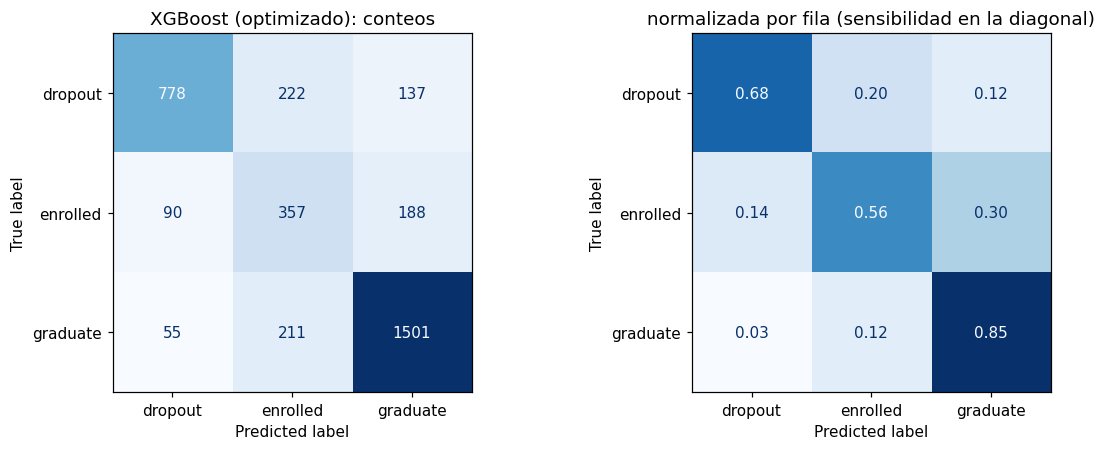

Sensibilidad por clase: {'dropout': np.float64(0.684), 'enrolled': np.float64(0.562), 'graduate': np.float64(0.849)} | exactitud: 0.745


In [19]:
def estimator_of(name):
    if name in BASE: return BASE[name]
    if name.endswith(" (optimizado)"): return SEARCH[name.replace(" (optimizado)", "")]["search"].best_estimator_
    if name == "Votación dura": return voting("hard")
    if name == "Votación suave": return voting("soft")
    if name.startswith("Stacking"): return stacking()
    if name.startswith("Bagging"):
        return Pipeline([FEAT, ("prep", prep_tree()), ("clf", BaggingClassifier(estimator=DecisionTreeClassifier(random_state=SEED), n_estimators=N_TREES[-1], random_state=SEED))])
    if name.startswith("AdaBoost"):
        return Pipeline([FEAT, ("prep", prep_tree()), ("clf", AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, random_state=SEED), n_estimators=N_ROUNDS, random_state=SEED))])
    if name == "Árbol sin límite": return Pipeline([FEAT, ("prep", prep_tree()), ("clf", DecisionTreeClassifier(random_state=SEED))])
    if name.startswith("Tocón"): return Pipeline([FEAT, ("prep", prep_tree()), ("clf", DecisionTreeClassifier(max_depth=1, random_state=SEED))])
    raise KeyError(name)

pred_best = cross_val_predict(clone(estimator_of(BEST1)), X, yi, cv=folds, n_jobs=-1)
cm = confusion_matrix(yi, pred_best, labels=range(len(CLASSES)))
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax[0], cmap="Blues", colorbar=False, values_format="d")
ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=CLASSES).plot(ax=ax[1], cmap="Blues", colorbar=False, values_format=".2f")
ax[0].set_title(f"{BEST1}: conteos"); ax[1].set_title("normalizada por fila (sensibilidad en la diagonal)")
for a in ax: a.grid(False)
plt.tight_layout(); plt.show()
print("Sensibilidad por clase:", {c: round(cm[i, i] / cm[i].sum(), 3) for i, c in enumerate(CLASSES)}, "| exactitud:", round(accuracy_score(yi, pred_best), 3))

Resumen por familia (F1 macro, validación cruzada de 5 pliegues):

- base (Práctica 3): mejor = **SVM** con 0.687 ± 0.012.
- votación / stacking: mejor = **Votación dura** con 0.693 ± 0.004.
- bagging optimizado: mejor = **Random Forest (optimizado)** con 0.690 ± 0.017.
- boosting optimizado: mejor = **XGBoost (optimizado)** con 0.698 ± 0.007.

El mejor modelo global es **XGBoost (optimizado)** (0.698 ± 0.007); el mejor base es SVM (0.687), es decir, los ensambles ganan **+0.011** de F1 macro sobre el mejor clasificador individual ya optimizado. La diferencia entre el primero y el segundo (Votación dura) es 0.004, **menor que la desviación entre pliegues**: son estadísticamente indistinguibles con estos datos.

# Parte 2. Bank Marketing

Datos: bank-additional-full.csv (Moro et al., 2014), 41 188 llamadas de telemarketing de un banco portugués; la etiqueta `y` indica si el cliente contrató el depósito a plazo. Como en la Tarea 4, se elimina duration (se conoce solo después de la llamada y casi determina el resultado: usarla sería fuga de información).

Reglas del experimento, tal como se piden:

* `X` es el archivo sin `duration` ni `y`; `y` vale 1 (yes) y 0 (no).
* El F1 macro de cada modelo sale de cross_validate(modelo, X, y, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=2026), scoring="f1_macro").
* Todo lo que se ajusta con datos (preprocesamiento, selección de atributos, balanceo, calibración, **umbral**) va dentro del modelo, para que en cada pliegue se ajuste solo con el entrenamiento del pliegue.

In [20]:
def find_bank():
    current = Path.cwd().resolve()
    for folder in (current, *current.parents):
        for sub in (".", "data", "datos"):
            f = folder / sub / "bank-additional-full.csv"
            if f.is_file(): return f
    raise FileNotFoundError("No se encontró bank-additional-full.csv junto al cuaderno (ni en data/).")

df = pd.read_csv(find_bank(), sep=";")
print("Dimensiones:", df.shape)
assert df.shape == (41188, 21), "El archivo debe tener 41 188 filas y 21 columnas"
yb = (df["y"] == "yes").astype(int)
Xb = df.drop(columns=["y", "duration"])
CV_B = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)
cat_b = [c for c in Xb.columns if not pd.api.types.is_numeric_dtype(Xb[c])]
num_b = [c for c in Xb.columns if c not in cat_b]
print(f"{Xb.shape[1]} atributos sin duration: {len(cat_b)} categóricos, {len(num_b)} numéricos | proporción de yes: {yb.mean():.4f} | duplicados: {int(Xb.assign(y=yb).duplicated().sum())}")
display(pd.DataFrame({"n": yb.value_counts().sort_index(), "%": (100 * yb.value_counts(normalize=True).sort_index()).round(1)}, index=["no (0)", "yes (1)"]))

Dimensiones: (41188, 21)
19 atributos sin duration: 10 categóricos, 9 numéricos | proporción de yes: 0.1127 | duplicados: 1784


,n,%
no (0),NaN,NaN
yes (1),NaN,NaN


Categóricos con 'unknown' (%): {'job': 0.8, 'marital': 0.2, 'education': 4.2, 'default': 20.9, 'housing': 2.4, 'loan': 2.4}
pdays = 999 (nunca contactado antes): 96.3 % | poutcome='nonexistent': 86.3 %
Valores distintos de los 5 indicadores macroeconómicos: {'emp.var.rate': 10, 'cons.price.idx': 26, 'cons.conf.idx': 26, 'euribor3m': 316, 'nr.employed': 11}


,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
emp.var.rate,1.00,0.78,0.20,0.97,0.91
cons.price.idx,0.78,1.00,0.06,0.69,0.52
cons.conf.idx,0.20,0.06,1.00,0.28,0.10
euribor3m,0.97,0.69,0.28,1.00,0.95
nr.employed,0.91,0.52,0.10,0.95,1.00


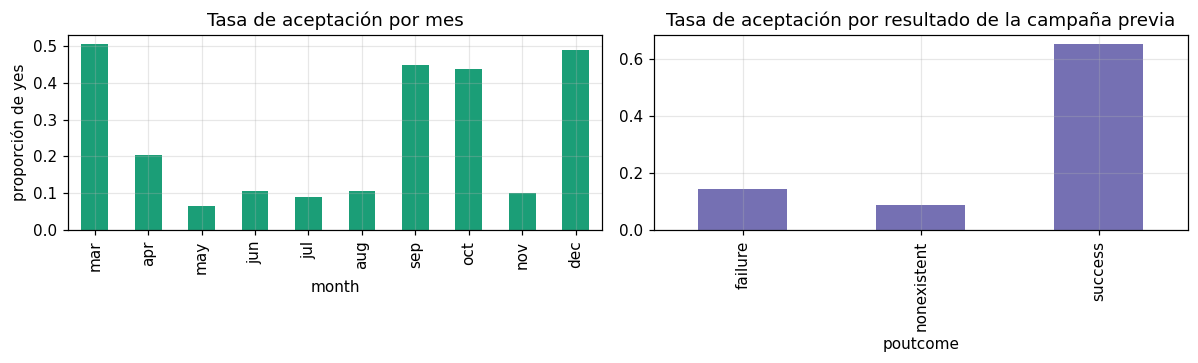

In [21]:
unk = (df[cat_b] == "unknown").mean().mul(100).round(1)
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
print("Categóricos con 'unknown' (%):", unk[unk > 0].to_dict())
print("pdays = 999 (nunca contactado antes):", f"{100 * (df.pdays == 999).mean():.1f} %", "| poutcome='nonexistent':", f"{100 * (df.poutcome == 'nonexistent').mean():.1f} %")
print("Valores distintos de los 5 indicadores macroeconómicos:", {c: int(df[c].nunique()) for c in macro})
display(df[macro].corr().round(2))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
df.groupby("month")["y"].apply(lambda s: (s == "yes").mean()).reindex(["mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]).plot.bar(ax=ax[0], color="#1b9e77")
ax[0].set_title("Tasa de aceptación por mes"); ax[0].set_ylabel("proporción de yes")
df.groupby("poutcome")["y"].apply(lambda s: (s == "yes").mean()).plot.bar(ax=ax[1], color="#7570b3"); ax[1].set_title("Tasa de aceptación por resultado de la campaña previa")
plt.tight_layout(); plt.show()

Lectura de los datos.

* Desbalance fuerte (≈ 11 % yes) y problema binario: el F1 macro castiga ignorar a la clase yes, y con umbral 0.5 un modelo bien calibrado casi nunca la predice.
* pdays = 999 no es un número, es un centinela ("nunca contactado"), y poutcome = nonexistent lo acompaña. Se separa en un indicador contactado_antes y un pdays limpio (0 si no se contactó).
* unknown en default, education, housing, loan, job, marital se conserva como una categoría más: que el dato falte puede ser informativo.
* Los cinco indicadores macroeconómicos están casi colineales y toman muy pocos valores distintos (identifican el periodo de la campaña). Como el archivo está ordenado en el tiempo y la validación cruzada mezcla las filas (shuffle=True), un modelo puede "reconocer" el periodo desde un pliegue de entrenamiento: la estimación de CV es algo optimista respecto a predecir una campaña futura. Se advierte, pero se respeta el protocolo pedido.

# Preprocesamiento dentro del modelo

| Paso | Qué hace | Para quién |
|---|---|---|
| `BankFeatures` | Crea `contactado_antes` (pdays ≠ 999) y reemplaza 999 por 0 en `pdays`; añade `log_campaign` | todos |
| one-hot + `StandardScaler` | categóricos a indicadoras, numéricos a media 0 y desv. 1 | logística, kNN, Naive Bayes, selección |
| one-hot + sin escalar | los cortes de un árbol no dependen de la escala | árbol, bosques, boosting |
| `SelectKBest` | opcional, mantiene los k atributos con mayor F | logística, kNN |
| `TunedThresholdClassifierCV` | **umbral de decisión** que maximiza el F1 macro, elegido con validación cruzada *interna* del entrenamiento del pliegue (5 pliegues) y modelo final reentrenado con todo el entrenamiento | los que dan probabilidades |
| `RandomUnderSampler` / `SMOTE` | balanceo de clases *solo* sobre el entrenamiento del pliegue (Pipeline de `imbalanced-learn`); nunca se toca el pliegue de validación | opcional |

In [22]:
from sklearn.model_selection import TunedThresholdClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
import imblearn

class BankFeatures(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        X["contactado_antes"] = (X["pdays"] != 999).astype(int)
        X["pdays"] = X["pdays"].where(X["pdays"] != 999, 0)
        X["log_campaign"] = np.log1p(X["campaign"])
        return X

NUM_B = num_b + ["contactado_antes", "log_campaign"]
def ohe_b(): return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
def prep_lin_b():  return ColumnTransformer([("cat", ohe_b(), cat_b), ("num", StandardScaler(), NUM_B)])
def prep_tree_b(): return ColumnTransformer([("cat", ohe_b(), cat_b), ("num", "passthrough", NUM_B)])
BF = ("feat", BankFeatures())

def thr(est):
    return TunedThresholdClassifierCV(est, scoring="f1_macro", response_method="predict_proba", cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                                      thresholds=np.linspace(0.02, 0.9, 89), refit=True, n_jobs=1)

def lr_b(**kw): return LogisticRegression(max_iter=3000, **kw)
print("imbalanced-learn", imblearn.__version__)

imbalanced-learn 0.14.2


# Primera ronda: preprocesamiento, balanceo, umbral y clasificadores individuales

Se parte de la regresión logística de la Tarea 4 (one-hot + estandarizar, umbral 0.5) y se añade, una cosa a la vez, cada ingrediente para ver cuánto aporta. Los clasificadores sin optimización fina usan hiperparámetros razonables fijos; los más prometedores se optimizan en la sección siguiente.

In [23]:
B_ROWS = []
def run_b(name, est, config=""):
    t0 = time.perf_counter()
    r = bench(name, est, Xb, yb, CV_B, 1, n_jobs=-1, config=config)
    B_ROWS.append(r)
    print(f"{name:52s} F1 macro = {r['F1 media']:.3f} ± {r['F1 desv.']:.3f} | sens(yes) = {r['sensibilidad']:.3f} | fit = {r['t. entrenamiento (s)']:.1f} s   ({time.perf_counter()-t0:.0f} s)")

run_b("Referencia: siempre 'no'", Pipeline([BF, ("prep", prep_lin_b()), ("clf", DummyClassifier(strategy="most_frequent"))]), "clase mayoritaria")
run_b("Logística (Tarea 4), umbral 0.5", Pipeline([BF, ("prep", prep_lin_b()), ("clf", lr_b())]), "one-hot + estandarizar")
run_b("Logística, class_weight=balanced", Pipeline([BF, ("prep", prep_lin_b()), ("clf", lr_b(class_weight="balanced"))]), "peso por clase")
run_b("Logística + umbral óptimo", thr(Pipeline([BF, ("prep", prep_lin_b()), ("clf", lr_b())])), "umbral dentro del modelo")
run_b("Logística + SelectKBest(30) + umbral", thr(Pipeline([BF, ("prep", prep_lin_b()), ("sel", SelectKBest(f_classif, k=30)), ("clf", lr_b())])), "selección de atributos")
run_b("Logística + submuestreo + umbral", thr(ImbPipeline([BF, ("prep", prep_lin_b()), ("bal", RandomUnderSampler(random_state=SEED)), ("clf", lr_b())])), "RandomUnderSampler en entrenamiento")
run_b("Logística + SMOTE + umbral", thr(ImbPipeline([BF, ("prep", prep_lin_b()), ("bal", SMOTE(random_state=SEED)), ("clf", lr_b())])), "SMOTE en entrenamiento")

Referencia: siempre 'no'                             F1 macro = 0.470 ± 0.000 | sens(yes) = 0.000 | fit = 0.1 s   (0 s)
Logística (Tarea 4), umbral 0.5                      F1 macro = 0.642 ± 0.011 | sens(yes) = 0.228 | fit = 0.6 s   (1 s)
Logística, class_weight=balanced                     F1 macro = 0.675 ± 0.005 | sens(yes) = 0.627 | fit = 0.7 s   (1 s)
Logística + umbral óptimo                            F1 macro = 0.708 ± 0.007 | sens(yes) = 0.520 | fit = 4.9 s   (5 s)
Logística + SelectKBest(30) + umbral                 F1 macro = 0.707 ± 0.006 | sens(yes) = 0.528 | fit = 3.9 s   (4 s)
Logística + submuestreo + umbral                     F1 macro = 0.704 ± 0.006 | sens(yes) = 0.499 | fit = 2.5 s   (3 s)
Logística + SMOTE + umbral                           F1 macro = 0.708 ± 0.006 | sens(yes) = 0.506 | fit = 7.4 s   (8 s)


In [24]:
run_b("Árbol (profundidad 6) + umbral", thr(Pipeline([BF, ("prep", prep_tree_b()), ("clf", DecisionTreeClassifier(max_depth=6, min_samples_leaf=30, random_state=SEED))])), "max_depth=6, min_samples_leaf=30")
run_b("Naive Bayes gaussiano + umbral", thr(Pipeline([BF, ("prep", prep_lin_b()), ("clf", GaussianNB())])), "var_smoothing por defecto")
run_b("kNN (k=100) + umbral", thr(Pipeline([BF, ("prep", prep_lin_b()), ("sel", SelectKBest(f_classif, k=30)), ("clf", KNeighborsClassifier(n_neighbors=100, weights="distance"))])), "k=100, SelectKBest(30)")
run_b("Random Forest (por defecto) + umbral", thr(Pipeline([BF, ("prep", prep_tree_b()), ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=1, random_state=SEED))])), "300 árboles, min_samples_leaf=5")
run_b("HistGradientBoosting + umbral", thr(Pipeline([BF, ("prep", prep_tree_b()), ("clf", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, random_state=SEED))])), "lr=0.05, 300 iteraciones")

Árbol (profundidad 6) + umbral                       F1 macro = 0.714 ± 0.007 | sens(yes) = 0.560 | fit = 2.8 s   (3 s)
Naive Bayes gaussiano + umbral                       F1 macro = 0.662 ± 0.008 | sens(yes) = 0.518 | fit = 2.3 s   (3 s)
kNN (k=100) + umbral                                 F1 macro = 0.673 ± 0.009 | sens(yes) = 0.422 | fit = 7.9 s   (10 s)
Random Forest (por defecto) + umbral                 F1 macro = 0.718 ± 0.006 | sens(yes) = 0.541 | fit = 60.4 s   (62 s)
HistGradientBoosting + umbral                        F1 macro = 0.717 ± 0.007 | sens(yes) = 0.538 | fit = 11.0 s   (12 s)


# Segunda ronda: optimización de bagging y boosting

Se optimizan Random Forest, Extra-Trees, XGBoost y LightGBM con `RandomizedSearchCV` (`N_ITER_B` configuraciones cada uno, con los mismos espacios de la Parte 1 más `scale_pos_weight`/`class_weight` para el desbalance). Dos decisiones para que la búsqueda sea barata y honesta:

* El criterio de selección es el **mejor F1 macro que alcanza cada configuración al elegir su umbral en el pliegue de validación** (`f1_best_thr`). Es optimista por construcción, pero solo se usa para *ordenar* configuraciones: permite comparar configuraciones por su calidad de ranking de probabilidades sin que el umbral 0.5 las confunda.
* La búsqueda usa 3 pliegues propios (semilla distinta de la de evaluación). Luego, el modelo ganador de cada familia se evalúa **de nuevo** con el protocolo oficial (5 pliegues, semilla 2026, umbral elegido dentro del modelo con `TunedThresholdClassifierCV`), que es el número que se reporta. Aun así, la configuración se eligió viendo estos mismos datos, por lo que se añade una columna de control con pliegues nuevos.

In [25]:
N_ITER_B = int(os.environ.get("N_ITER_B", 40))
if QUICK: N_ITER_B = 4

def f1_best_thr(est, Xv, yv):
    p = est.predict_proba(Xv)[:, 1]
    return max(f1_score(yv, p >= t, average="macro") for t in np.linspace(0.04, 0.8, 39))

SEARCH_B = {}
CV_SEARCH = StratifiedKFold(3, shuffle=True, random_state=7)
def search_b(name, pipe, space):
    rs = RandomizedSearchCV(pipe, space, n_iter=N_ITER_B, scoring=f1_best_thr, cv=CV_SEARCH, n_jobs=-1, random_state=SEED, refit=False, error_score=np.nan)
    t0 = time.perf_counter(); rs.fit(Xb, yb)
    SEARCH_B[name] = {"search": rs, "time": time.perf_counter() - t0}
    print(f"{name:14s} configs={N_ITER_B}  mejor F1 macro (umbral óptimo, 3 pliegues)={rs.best_score_:.4f}  búsqueda={SEARCH_B[name]['time']:.0f} s")
    print("   mejor configuración:", {k.replace('clf__estimator__', '').replace('clf__', ''): (round(v, 4) if isinstance(v, float) else v) for k, v in rs.best_params_.items()})

CWB = [None, "balanced", {1: 3.0}]
common_t = {"clf__max_features": ["sqrt", "log2", 0.3, 0.5], "clf__min_samples_leaf": randint(1, 61), "clf__max_depth": [None, 8, 12, 16, 24],
            "clf__criterion": ["gini", "entropy", "log_loss"], "clf__class_weight": CWB + ["balanced_subsample"]}
rfb = Pipeline([BF, ("prep", prep_tree_b()), ("clf", RandomForestClassifier(n_estimators=150 if not QUICK else 50, n_jobs=1, random_state=SEED))])
etb = Pipeline([BF, ("prep", prep_tree_b()), ("clf", ExtraTreesClassifier(n_estimators=150 if not QUICK else 50, n_jobs=1, random_state=SEED))])
search_b("Random Forest", rfb, dict(common_t, clf__max_samples=uniform(0.4, 0.6)))
search_b("Extra-Trees", etb, dict(common_t, clf__bootstrap=[True, False]))

Random Forest  configs=40  mejor F1 macro (umbral óptimo, 3 pliegues)=0.7193  búsqueda=91 s
   mejor configuración: {'class_weight': None, 'criterion': 'log_loss', 'max_depth': None, 'max_features': 0.5, 'max_samples': np.float64(0.6369), 'min_samples_leaf': 8}
Extra-Trees    configs=40  mejor F1 macro (umbral óptimo, 3 pliegues)=0.7182  búsqueda=180 s
   mejor configuración: {'bootstrap': True, 'class_weight': {1: 3.0}, 'criterion': 'entropy', 'max_depth': 16, 'max_features': 0.5, 'min_samples_leaf': 15}


In [26]:
class WeightedBoosterB(WeightedBooster):          
    pass
xgb_b = XGBClassifier(tree_method="hist", n_jobs=1, random_state=SEED, verbosity=0, objective="binary:logistic")
lgb_b = LGBMClassifier(n_jobs=1, random_state=SEED, verbose=-1, subsample_freq=1)
common_bb = {"clf__estimator__learning_rate": loguniform(0.01, 0.3), "clf__estimator__n_estimators": randint(100, 401),
             "clf__estimator__reg_lambda": loguniform(0.1, 50), "clf__estimator__reg_alpha": loguniform(1e-3, 5),
             "clf__estimator__subsample": uniform(0.5, 0.5), "clf__estimator__colsample_bytree": uniform(0.4, 0.6), "clf__class_weight": CWB}
xgbp = Pipeline([BF, ("prep", prep_tree_b()), ("clf", WeightedBoosterB(xgb_b))])
lgbp = Pipeline([BF, ("prep", prep_tree_b()), ("clf", WeightedBoosterB(lgb_b))])
search_b("XGBoost", xgbp, dict(common_bb, **{"clf__estimator__max_depth": randint(2, 9), "clf__estimator__min_child_weight": loguniform(1, 30),
                                             "clf__estimator__gamma": uniform(0, 2)}))
search_b("LightGBM", lgbp, dict(common_bb, **{"clf__estimator__num_leaves": randint(4, 49), "clf__estimator__max_depth": [-1, 4, 6, 8],
                                              "clf__estimator__min_child_samples": randint(10, 101), "clf__estimator__min_split_gain": uniform(0, 1)}))

XGBoost        configs=40  mejor F1 macro (umbral óptimo, 3 pliegues)=0.7204  búsqueda=29 s
   mejor configuración: {'class_weight': 'balanced', 'colsample_bytree': np.float64(0.9093), 'gamma': np.float64(1.4435), 'learning_rate': np.float64(0.0223), 'max_depth': 7, 'min_child_weight': np.float64(5.3629), 'n_estimators': 306, 'reg_alpha': np.float64(0.0381), 'reg_lambda': np.float64(0.1171), 'subsample': np.float64(0.5539)}
LightGBM       configs=40  mejor F1 macro (umbral óptimo, 3 pliegues)=0.7193  búsqueda=17 s
   mejor configuración: {'class_weight': None, 'colsample_bytree': np.float64(0.5747), 'learning_rate': np.float64(0.0801), 'max_depth': 4, 'min_child_samples': 69, 'min_split_gain': np.float64(0.3664), 'n_estimators': 289, 'num_leaves': 47, 'reg_alpha': np.float64(0.0798), 'reg_lambda': np.float64(3.9711), 'subsample': np.float64(0.5232)}


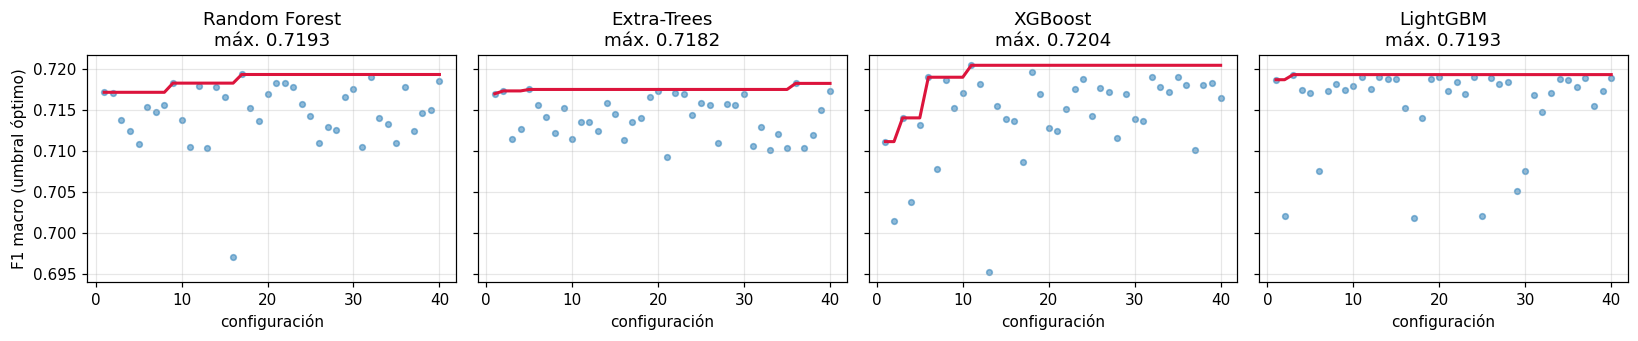

In [27]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for a, (name, d) in zip(ax, SEARCH_B.items()):
    s = np.asarray(d["search"].cv_results_["mean_test_score"], float)
    a.scatter(range(1, len(s) + 1), s, s=14, alpha=.5); a.plot(range(1, len(s) + 1), np.fmax.accumulate(s), color="crimson", lw=2)
    a.set_title(f"{name}\nmáx. {np.nanmax(s):.4f}"); a.set_xlabel("configuración")
ax[0].set_ylabel("F1 macro (umbral óptimo)"); plt.tight_layout(); plt.show()

Con la mejor configuración de cada familia se arma el modelo definitivo (con el umbral elegido dentro del modelo) y se evalúa con el protocolo oficial. Después se prueban **ensambles de los mejores**: votación suave y *stacking* con meta-modelo logístico, también con umbral dentro. Los ensambles reciben los modelos ya con sus hiperparámetros fijos; la diversidad viene de combinar una familia lineal (logística) con bosques y boosting.

In [28]:
def tuned_est(name):
    rs = SEARCH_B[name]["search"]; est = clone({"Random Forest": rfb, "Extra-Trees": etb, "XGBoost": xgbp, "LightGBM": lgbp}[name])
    return est.set_params(**rs.best_params_)
def short_b(name):
    return ", ".join(f"{k.replace('clf__estimator__','').replace('clf__','')}={v:.3g}" if isinstance(v, (float, np.floating)) else f"{k.replace('clf__estimator__','').replace('clf__','')}={v}"
                     for k, v in SEARCH_B[name]["search"].best_params_.items())
for name in SEARCH_B:
    run_b(f"{name} (optimizado) + umbral", thr(tuned_est(name)), short_b(name))
    B_ROWS[-1]["t. búsqueda (s)"] = SEARCH_B[name]["time"]

Random Forest (optimizado) + umbral                  F1 macro = 0.719 ± 0.007 | sens(yes) = 0.536 | fit = 44.2 s   (45 s)
Extra-Trees (optimizado) + umbral                    F1 macro = 0.716 ± 0.006 | sens(yes) = 0.527 | fit = 58.8 s   (59 s)
XGBoost (optimizado) + umbral                        F1 macro = 0.718 ± 0.006 | sens(yes) = 0.534 | fit = 13.7 s   (14 s)
LightGBM (optimizado) + umbral                       F1 macro = 0.718 ± 0.008 | sens(yes) = 0.526 | fit = 5.2 s   (6 s)


In [29]:
lr_pipe = Pipeline([BF, ("prep", prep_lin_b()), ("clf", lr_b())])
def mem(): return [(n, clone(e)) for n, e in members]
members = [("lr", lr_pipe), ("rf", tuned_est("Random Forest")), ("xgb", tuned_est("XGBoost")), ("lgb", tuned_est("LightGBM"))]
run_b("Votación suave (LR+RF+XGB+LGBM) + umbral", thr(VotingClassifier(mem(), voting="soft", n_jobs=1)), "promedio de probabilidades")
run_b("Stacking (LR+RF+XGB+LGBM; meta logística) + umbral",
      thr(StackingClassifier(mem(), final_estimator=LogisticRegression(max_iter=2000), cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
                             stack_method="predict_proba", n_jobs=1)), "meta-modelo logístico, 3 pliegues internos")

Votación suave (LR+RF+XGB+LGBM) + umbral             F1 macro = 0.719 ± 0.006 | sens(yes) = 0.538 | fit = 62.4 s   (63 s)
Stacking (LR+RF+XGB+LGBM; meta logística) + umbral   F1 macro = 0.719 ± 0.006 | sens(yes) = 0.537 | fit = 193.5 s   (195 s)


# Tabla de modelos probados y matriz de confusión del mejor

La columna *F1 pliegues nuevos* repite la evaluación del modelo con otra partición (3 × 5 pliegues, semilla distinta): como la configuración se escogió viendo los pliegues oficiales, esta columna indica cuánto de la ventaja podría deberse a esa selección.

In [30]:
tab_b, show_b = fmt_table(B_ROWS, "sensibilidad yes")
pd.set_option("display.max_colwidth", 120)
display(show_b)
BEST_B = tab_b.iloc[0]["modelo"]
print("Mejor modelo de Bank Marketing:", BEST_B)

,modelo,F1 macro (media ± desv.),sensibilidad yes,t. entrenamiento (s),configuración
1,Random Forest (optimizado) + umbral,0.719 ± 0.007,0.536,44.22,"class_weight=None, criterion=log_loss, max_depth=None, max_features=0.5, max_samples=0.637, min_samples_leaf=8"
2,Stacking (LR+RF+XGB+LGBM; meta logística) + umbral,0.719 ± 0.006,0.537,193.46,"meta-modelo logístico, 3 pliegues internos"
3,Votación suave (LR+RF+XGB+LGBM) + umbral,0.719 ± 0.006,0.538,62.41,promedio de probabilidades
4,Random Forest (por defecto) + umbral,0.718 ± 0.006,0.541,60.43,"300 árboles, min_samples_leaf=5"
5,XGBoost (optimizado) + umbral,0.718 ± 0.006,0.534,13.73,"class_weight=balanced, colsample_bytree=0.909, gamma=1.44, learning_rate=0.0223, max_depth=7, min_child_weight=5.36,..."
6,LightGBM (optimizado) + umbral,0.718 ± 0.008,0.526,5.18,"class_weight=None, colsample_bytree=0.575, learning_rate=0.0801, max_depth=4, min_child_samples=69, min_split_gain=0..."
7,HistGradientBoosting + umbral,0.717 ± 0.007,0.538,11.02,"lr=0.05, 300 iteraciones"
8,Extra-Trees (optimizado) + umbral,0.716 ± 0.006,0.527,58.76,"bootstrap=True, class_weight={1: 3.0}, criterion=entropy, max_depth=16, max_features=0.5, min_samples_leaf=15"
9,Árbol (profundidad 6) + umbral,0.714 ± 0.007,0.560,2.79,"max_depth=6, min_samples_leaf=30"
10,Logística + umbral óptimo,0.708 ± 0.007,0.520,4.93,umbral dentro del modelo


Mejor modelo de Bank Marketing: Random Forest (optimizado) + umbral


F1 macro del mejor modelo en pliegues nuevos: 0.718 ± 0.007


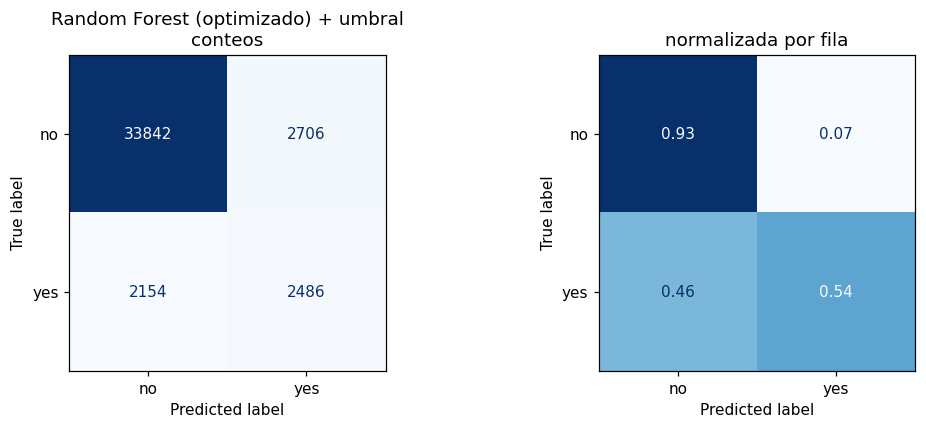

Sensibilidad (yes) = 0.536 | precisión (yes) = 0.479 | especificidad = 0.926 | exactitud = 0.882


In [31]:
def est_b(name):
    table = {
        "Logística (Tarea 4), umbral 0.5": lr_pipe, "Logística + umbral óptimo": thr(lr_pipe)}
    if name in table: return clone(table[name])
    for fam in SEARCH_B:
        if name.startswith(fam): return thr(tuned_est(fam))
    if name.startswith("Votación suave"): return thr(VotingClassifier(mem(), voting="soft", n_jobs=1))
    if name.startswith("Stacking"): return thr(StackingClassifier(mem(), final_estimator=LogisticRegression(max_iter=2000), cv=StratifiedKFold(3, shuffle=True, random_state=SEED), stack_method="predict_proba", n_jobs=1))
    raise KeyError(name)

best_est_b = est_b(BEST_B)
fresh_b = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=1 if QUICK else 2, random_state=11).split(Xb, yb))
f1_fresh = cross_validate(clone(best_est_b), Xb, yb, cv=fresh_b, scoring="f1_macro", n_jobs=-1)["test_score"]
print(f"F1 macro del mejor modelo en pliegues nuevos: {f1_fresh.mean():.3f} ± {f1_fresh.std(ddof=1):.3f}")

pred_b = cross_val_predict(clone(best_est_b), Xb, yb, cv=CV_B, n_jobs=-1)
cmb = confusion_matrix(yb, pred_b)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(cmb, display_labels=["no", "yes"]).plot(ax=ax[0], cmap="Blues", colorbar=False, values_format="d")
ConfusionMatrixDisplay(cmb / cmb.sum(axis=1, keepdims=True), display_labels=["no", "yes"]).plot(ax=ax[1], cmap="Blues", colorbar=False, values_format=".2f")
ax[0].set_title(f"{BEST_B}\nconteos"); ax[1].set_title("normalizada por fila")
for a in ax: a.grid(False)
plt.tight_layout(); plt.show()
tn, fp, fn, tp = cmb.ravel()
print(f"Sensibilidad (yes) = {tp/(tp+fn):.3f} | precisión (yes) = {tp/(tp+fp):.3f} | especificidad = {tn/(tn+fp):.3f} | exactitud = {(tp+tn)/cmb.sum():.3f}")

# ¿Funcionó lo mismo que en la deserción?

**Qué aportó cada ingrediente (F1 macro):**

- *Umbral*: la logística de la Tarea 4 con umbral 0.5 queda en 0.642 (sensibilidad de yes 0.23); solo con elegir el umbral dentro del modelo sube a 0.708 (sensibilidad 0.52), es decir **+0.066** sin cambiar de modelo. En este problema el umbral pesa más que la elección del clasificador.
- *Mejor modelo individual*: Random Forest (optimizado) + umbral con 0.719 ± 0.007, +0.011 sobre la logística con umbral.
- *Ensambles de modelos*: Votación suave (LR+RF+XGB+LGBM) + umbral 0.719; Stacking (LR+RF+XGB+LGBM; meta logística) + umbral 0.719.
- *Mejor global*: **Random Forest (optimizado) + umbral**, 0.719 ± 0.007; en pliegues nuevos 0.718.

**Comparación con la deserción y por qué.**
enrolled; en el banco, sin duration el perfil del cliente y el contexto macroeconómico solo permiten un AUC alrededor de 0.8. Por eso las diferencias entre buenos modelos son de milésimas y suelen caer dentro de la desviación entre pliegues. Y en ambos, un ensamble no puede corregir lo que ningún miembro ve.
* **Qué cambia.** (1) *Tamaño y desbalance*: el banco tiene 41 188 filas y solo 11 % de positivos; con 10 veces más datos, los modelos de alta capacidad (boosting, bosques) pueden aprender interacciones (mes × indicadores macro × resultado previo) que en 3 539 estudiantes quedarían como ruido. (2) *Problema binario con una clase rara*: el F1 macro depende casi por completo de dónde se coloca el umbral, algo que en la deserción (tres clases, ya cercanas al equilibrio con pesos) no domina. (3) *Estructura de los atributos*: el banco mezcla categóricas de baja cardinalidad con cinco indicadores macro colineales que actúan como proxy del periodo; los árboles las aprovechan con cortes, mientras que un modelo lineal necesita estandarizarlos y los trata como una sola dirección. (4) *Lo que funciona en un problema no se transfiere automáticamente*: en la deserción el SVM y la logística bien regularizadas eran los mejores individuales porque la señal es casi lineal y hay pocos datos; en el banco el valor de pasar a no linealidades depende de cuánto mejoren sobre la logística con umbral, que es la cifra de la tabla.
* **Advertencia de validez.** Los datos del banco están ordenados por fecha y la validación mezcla filas; el desempeño real sobre una campaña futura sería menor que el de la tabla. Además la configuración final se eligió sobre los mismos datos (por eso se reporta la columna de pliegues nuevos).

# Modelo final y archivo .joblib

Se reentrena el mejor modelo con **todo** bank-additional-full.csv (sin `duration`) y se guarda el Pipeline completo (preprocesamiento + clasificador + umbral), de modo que modelo.predict(X) recibe el DataFrame crudo con las 19 columnas originales.

In [32]:
slug = re.sub(r"[^a-z0-9]+", "_", BEST_B.lower()).strip("_")
MODEL_NAME = f"{slug}_modelo.joblib"
final_b = clone(best_est_b).fit(Xb, yb)
joblib.dump(final_b, MODEL_NAME, compress=3)
reloaded = joblib.load(MODEL_NAME)
assert np.array_equal(reloaded.predict(Xb.head(500)), final_b.predict(Xb.head(500)))
p_all = final_b.predict(Xb)
print("Archivo:", MODEL_NAME, f"({Path(MODEL_NAME).stat().st_size/1e6:.1f} MB)")
print("Umbral aprendido:", getattr(final_b, "best_threshold_", "n/a"), "| proporción predicha como yes (entrenamiento):", round(float(p_all.mean()), 3))
tab_b.drop(columns="_folds").to_csv("resultados_bank.csv", index=False)
tab_all.drop(columns="_folds").to_csv("resultados_desercion.csv", index=False)

Archivo: random_forest_optimizado_umbral_modelo.joblib (6.6 MB)
Umbral aprendido: 0.27 | proporción predicha como yes (entrenamiento): 0.124


# Conclusiones

**Lo que mostraron los números de esta ejecución:**

- *Bagging y varianza (Parte 1).* Un árbol sin límite tiene F1 macro 0.591; bagging con 400 árboles, 0.662. La inestabilidad de la predicción ante cambios de muestra cae 70 %. Random Forest optimizado llega a 0.690 y Extra-Trees a 0.690, frente a 0.687 del mejor clasificador base (SVM).
- *Boosting y sesgo (Parte 1).* El tocón tiene 0.508 y AdaBoost, 0.653; con XGBoost 0.698 y LightGBM 0.693.
- *Combinar los cinco base (Parte 1).* Votación dura 0.693, suave 0.679, stacking 0.669; la correlación media de errores entre los cinco es 0.62, lo que limita la ganancia.
- *Parte 1, global.* El mejor es XGBoost (optimizado) con 0.698 ± 0.007: +0.011 sobre el mejor base.
- *Parte 2, Bank Marketing.* Mejor: Random Forest (optimizado) + umbral, 0.719 ± 0.007, contra 0.642 de la logística de la Tarea 4 con umbral 0.5 y 0.708 de la logística con umbral óptimo.

**Qué aportó cada familia de ensambles.**

* **Bagging / bosques** reducen varianza. Ayudan más cuanto más inestable es el modelo base y cuanto más datos hay para que los árboles profundos no memoricen ruido; con pocos datos y ruido alto (la deserción) su ganancia sobre un modelo regularizado es pequeña, y con muchos datos y interacciones (el banco) es más clara. Son robustos a la escala y a los hiperparámetros: la meseta de la búsqueda aparece pronto.
* **Boosting** reduce sesgo y es el que más sabe aprovechar interacciones y atributos de poco valor individual; a cambio es más sensible a los hiperparámetros (tasa de aprendizaje, profundidad, regularización) y tiende a sobreajustar cuando la señal es débil o la etiqueta ruidosa, como en enrolled.
* **Votación y stacking** solo pueden ganar si los errores de los miembros son distintos. En la deserción los cinco clasificadores base se equivocan en los mismos estudiantes (correlación de errores alta), por lo que la ganancia es mínima; en el banco, combinar un lineal con bosques y boosting aporta diversidad, pero al final lo que más pesa es el umbral.
* **Costo.** Los ensambles cuestan más en entrenamiento (la columna de tiempo): bosques y boosting son cientos de modelos y stacking multiplica el costo por la validación cruzada interna. Si la ganancia es de milésimas dentro de la desviación entre pliegues, la logística o el SVM bien ajustados son una opción defendible por simplicidad.

**Qué características de los conjuntos explican las diferencias.**

| | Deserción | Bank Marketing |
|---|---|---|
| Instancias | 3 539 | 41 188 |
| Clases | 3 (minoritaria ≈ 18 %) | 2 (minoritaria ≈ 11 %) |
| Atributos | 36 (1er semestre), 9 nominales con alta cardinalidad | 19, 10 categóricos de baja cardinalidad, 5 macro colineales |
| Señal | casi monótona en el rendimiento académico; enrolled es un estado intermedio | débil sin duration; dominada por contexto (mes, periodo, resultado previo) |
| Qué decide el F1 macro | el equilibrio entre tres clases | el umbral sobre una clase rara |

Con pocos datos, ruido en una clase intermedia y errores muy correlacionados entre modelos, los ensambles aportan poco sobre clasificadores ya bien ajustados; con muchos datos, desbalance fuerte e interacciones entre atributos, los ensambles de árboles y, sobre todo, ajustar el umbral con rigor, sí cambian el resultado. Las cifras de esta ejecución (arriba) son la evidencia; las diferencias menores que la desviación entre pliegues no deben leerse como superioridad.

# Referencias

Alban, M., & Mauricio, D. (2019). Predicting university dropout through data mining: A systematic literature. Indian Journal of Science and Technology, 12(4), 1–12. https://doi.org/10.17485/ijst/2019/v12i4/139729

Moro, S., Cortez, P., & Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. Decision Support Systems, 62, 22–31. https://doi.org/10.1016/j.dss.2014.03.001

Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021). Predict students' dropout and academic success [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89

# Declaración de uso de IA

Para esta práctica se utilizó la inteligencia artificial Anthropic Claude como herramienta de asistencia para la revisión, edición y mejora del formato de texto, así como el apoyo en la toma de sugerencias para la parte del código y la corrección de errores.